# 33 MeV D on Ta 

This notebook documents the steps taken to calibrate, aquire, and analyze data from activation foils used to unfold the neutron spectrum from 33 MeV D breakup on Ta.  

This Notebook is broken into the following main sections: <br\>
1) Simulated Results <br\>
2) Simulated Unfold <br\>
3) Calibration <br\>
4) Count Plan <br\>
5) Experimental Setup <br\>

The notebook has dependecies on PScripts, which can be cloned from:
https://github.com/jamesbevins/PyScripts

Once cloned, the path to the PyScripts/src directory must be added to the user's PYTHONPATH environement variable for this notebook to work.

In [1]:
pwd

u'/home/pyne-user/Dropbox/UCB/Research/ETAs/88Inch/Data/Experiments/Activation/33MeVTa_25Apr'

In [2]:
import os
import sys
import peakutils

import pandas as pd
import numpy as np
import copy as cp

from math import sqrt, exp, log
from datetime import datetime
from scipy.optimize import curve_fit
from peakutils.plot import plot as pplot

import matplotlib
matplotlib.use('Qt5Agg')
%matplotlib inline
from matplotlib import pyplot

# Path to PyScripts support functions 
from GeneralNuclear.Counting import parse_spe, simple_peak_counts, germanium_eff_exp, foil_count_time, \
                                    volume_solid_angle, optimal_count_plan, germanium_eff_poly, ge_peakfit, \
                                    get_peak_windows, find_best_fit,  germanium_eff, channel_statistics, count_plan
from GeneralNuclear.BasicNuclearCalcs import decay, production_decay, get_decay_const, fractional_solid_angle
from DataAnalysis.Stats import red_chisq, curve_fit_error4

/usr/local/lib/python2.7/dist-packages/matplotlib/__init__.py:1401: UserWarning:  This call to matplotlib.use() has no effect
because the backend has already been chosen;
matplotlib.use() must be called *before* pylab, matplotlib.pyplot,
or matplotlib.backends is imported for the first time.

  warnings.warn(_use_error_msg)


## Simulated Results

### MCNP

The experimental configuration was simulated in MCNP to get the expected reaction rates.  The Meulder's deuterons on 197Au was used as the source, and the foil pack was suspended center beam 34.62 cm from the wall.

The results are located at <path>\Dropbox\UCB\Research\ETAs\88Inch\Data\Simulated\Activation\33MevTa\BeamOnly\Model

They are sumarized at:

In [3]:
import os.path

simFoilPath = os.path.abspath('../../../Simulated/Activation/33MevTa/BeamOnly/33MeVTaFoils.xlsx')

if os.path.isfile(simFoilPath): 
    print 'The file exists at: {}'.format(simFoilPath)
else:
    print 'ERROR: The file DOES NOT exist at: {}'.format(simFoilPath)

The file exists at: /home/pyne-user/Dropbox/UCB/Research/ETAs/88Inch/Data/Simulated/Activation/33MevTa/BeamOnly/33MeVTaFoils.xlsx


## Simulated Unfold

Unfold of the MCNP results to test the theroretical ability to unfold given a set of reaction channels.  

### ****Analysis Pending****

## Calibration

The drawer was a little loose in the stack.  It was pushed to back right for repeatibility.

### Import source data

Calibration was performed using Cs137, Co60, Eu 152, Am241, and Ba133 sources @ 1, 5, 10, 1nd 18 cm.  The data are located in the Calibration folder. The lines used for energy and efficiency calibration are:

#### Energy Calibrations Only
Source   | Line (keV)| BR [%] 
-------- |:---------:|:------:
Y88      |392.87     |97.21   
Y88      |898.042    |93.7   
Y88      |1836.063   |99.2   


#### Energy And Efficiency Calibrations

Source   | Line (keV)| BR [%] 
-------- |:---------:|:------:
Cs137    |661.657    |85.10   
Co60     |1173.23    |99.85  
Co60     |1332.49    |99.98  
Am241    |59.54      |2.14   
Ba133    |80.9979    |32.9    
Ba133    |276.40     |7.16   
Ba133    |302.85     |18.34  
Ba133    |356.01     |62.05  
Eu152    |121.70     |28.53
Eu152    |244.70     |7.55
Eu152    |344.29     |26.59 
Eu152    |778.90     |12.93  
Eu152    |964.06     |14.51
Eu152    |1085.837   |10.11
Eu152    |1112.08    |13.67 
Eu152    |1408.01    |20.87

This data, along with the initial activity and decay information, is also located in the excel file located here:

In [4]:
calibSourcesPath = os.path.abspath('CalibrationSources.xlsx')

if os.path.isfile(calibSourcesPath): 
    print 'The file exists at: {}'.format(calibSourcesPath)
else:
    print 'ERROR: The file DOES NOT exist at: {}'.format(simFoilPath)

The file exists at: /Users/zacharysweger/Desktop/BANG/88_Data/Experiments/Activation/33MeVTa_25Apr/CalibrationSources.xlsx


Import the source and activity data and format for later analysis:

In [5]:
sources = pd.read_excel(calibSourcesPath, "Sources")
sources.columns = ['source', 'initActivity', 'initActRelUncert', 'initDate', 'halfLife']
sources.index = sources.source
del sources['source']
sources['initDate'] = pd.to_datetime(sources['initDate'])
sources['measDate'] = 0     

print "The calibration source data used: \n\n", sources

The calibration source data used: 

        initActivity  initActRelUncert   initDate      halfLife  measDate
source                                                                   
Am241         10.300           0.01165 1970-01-01  1.364420e+10         0
Eu152          1.062           0.01165 2009-01-01  4.263262e+08         0
Co60           1.007           0.01165 2009-01-01  1.663442e+08         0
Cs137          1.042           0.01165 2009-01-01  9.487232e+08         0
Ba133          1.078           0.01165 2009-01-01  3.327363e+08         0


Import the calibration line and branching ratio data:

In [6]:
lines = pd.read_excel(calibSourcesPath,"Lines")
lines.columns=['isotope','line','branchingRatio']
print "The calibration peak data used: \n\n", lines

The calibration peak data used: 

      isotope       line  branchingRatio
0       Am241    59.5409        0.359000
1   Cs137       661.6570        0.851000
2   Co60       1173.2300        0.998500
3   Co60       1332.4900        0.999826
4   Ba133        80.9979        0.329000
5   Ba133       276.4000        0.071600
6   Ba133       302.8500        0.183400
7   Ba133       356.0100        0.620500
8   Eu152       121.7000        0.285300
9   Eu152       244.7000        0.075500
10  Eu152       344.2900        0.265900
11  Eu152       778.9000        0.129300
12  Eu152       964.0600        0.145100
13  Eu152      1085.8370        0.101100
14  Eu152      1112.0800        0.136700
15  Eu152      1408.0100        0.208700


### Perform energy calibration

The energy calibration was performed using GammaVision and is contained in the .spe files.  Since the calibration files were saved as they were added to the calibration routine in GammaVision, the .spe files for each will change as the calibration converges.  The final calibration parameters achieved for each position (1, 5, 10, and 18 cm) are:

In [7]:
eCalibParams = {} #ax^2 +bx + c stored as (a,b,c)
eCalibParams[1] = (-2.936620E-009,  3.973171E-001, -4.793768E-001,)
eCalibParams[5] = (4.985228E-009, 3.971939E-001, -4.284930E-001)
eCalibParams[10] = (2.974716E-009, 3.972545E-001, -4.236994E-001)
eCalibParams[18] = (-1.307090E-010, 3.973216E-001, -4.008010E-001)
for p in eCalibParams:
    print "{} cm Shelf Energy Calibration: {}*ch^2 + {} * ch + {}".format(p, eCalibParams[p][0],
                                                              eCalibParams[p][1],
                                                              eCalibParams[p][2])

1 cm Shelf Energy Calibration: -2.93662e-09*ch^2 + 0.3973171 * ch + -0.4793768
10 cm Shelf Energy Calibration: 2.974716e-09*ch^2 + 0.3972545 * ch + -0.4236994
18 cm Shelf Energy Calibration: -1.30709e-10*ch^2 + 0.3973216 * ch + -0.400801
5 cm Shelf Energy Calibration: 4.985228e-09*ch^2 + 0.3971939 * ch + -0.428493


### Read in the calibration data

Read in all of the data taken for calibration.  

This procedure assumes: <br/>
1) That there is a folder with only calibration data in the format "isotope_position_anything.Spe".  For example, a valid naming convention is "Co60_1_8Feb17.Spe".  The first field is used to compare against the imported lines, and the second field is to build location dependent dictionaries. <br/>

The path the calibration data is:

In [8]:
calibDataPath = os.path.abspath('Calibration')

if os.path.isfile(calibSourcesPath): 
    print 'The file exists at: {}'.format(calibSourcesPath)
else:
    print 'ERROR: The file DOES NOT exist at: {}'.format(simFoilPath)

The file exists at: /Users/zacharysweger/Desktop/BANG/88_Data/Experiments/Activation/33MeVTa_25Apr/CalibrationSources.xlsx


In [9]:
# Variables to allow for multiple positions to be handled at once
posSet = False
posUsed = []

# Storage for parameters that vary by position
liveTime = {}
data = {}

# Loop over all files
for filename in os.listdir(calibDataPath):
    if filename.endswith(".Spe"): 
        name = os.path.splitext(filename)[0]
        
        # Read data from this file
        print "Processing:", filename
        (time, t, measDate, a, b, c, tmpData) = parse_spe(calibDataPath+'/'+filename)
        
        # Determine position, update data structures if necessary, and store data
        position = int(name.split('_')[1])
        if position not in posUsed:
            posUsed.append(position)
            liveTime[position] = {}
            data[position] = tmpData
            data[position].columns = [name.split('_')[0]]
        else: 
            data[position].loc[:,name.split('_')[0]] = tmpData['counts']
        if name.split('_')[0] in sources.index:
            sources.at[name.split('_')[0], 'measDate'] = measDate
            liveTime[position][name.split('_')[0]] = time
for p in posUsed:
    print "\nPosition = {} cm".format(p)
    print "LiveTime:", liveTime[p]
    print data[p].head(3)

Processing: Am241_1.Spe
Processing: Am241_10.Spe
Processing: Am241_18.Spe
Processing: Am241_5.Spe
Processing: Ba133_1.Spe
Processing: Ba133_10.Spe
Processing: Ba133_18.Spe
Processing: Ba133_5.Spe
Processing: Co60_1.Spe
Processing: Co60_10.Spe
Processing: Co60_18.Spe
Processing: Co60_5.Spe
Processing: Cs137_1.Spe
Processing: Cs137_10.Spe
Processing: Cs137_18.Spe
Processing: Cs137_5.Spe
Processing: Eu152_1.Spe
Processing: Eu152_10.Spe
Processing: Eu152_18.Spe
Processing: Eu152_5.Spe
Processing: Y88_1.Spe
Processing: Y88_10.Spe
Processing: Y88_18.Spe
Processing: Y88_5.Spe

Position = 1 cm
LiveTime: {'Am241': 126.0, 'Co60': 61.0, 'Ba133': 397.0, 'Cs137': 61.0, 'Eu152': 193.0}
   Am241  Ba133  Co60  Cs137  Eu152  Y88
0      0      0     0      0      0    0
1      0      0     0      0      0    0
2      0      0     0      0      0    0

Position = 10 cm
LiveTime: {'Am241': 61.0, 'Co60': 319.0, 'Ba133': 679.0, 'Cs137': 87.0, 'Eu152': 1664.0}
   Am241  Ba133  Co60  Cs137  Eu152  Y88
0      

### Calculate the peak counts

Determine the peak area for each of the lines considered.  Save the data in the lines dataframe. 

This procedure assumes: <br/>
1) That no significant background not associated with the calibration source is present.  No background subtraction is performed. <br/>  


------------------------
Position = 1 cm
------------------------
Am241


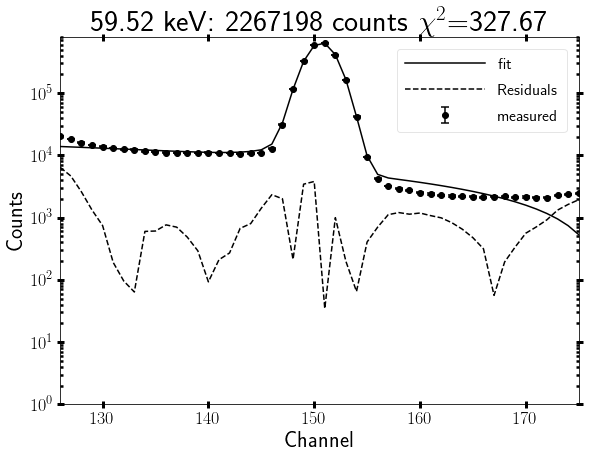


 Am241
Energy  Peak Area
59.52   2267197   1505




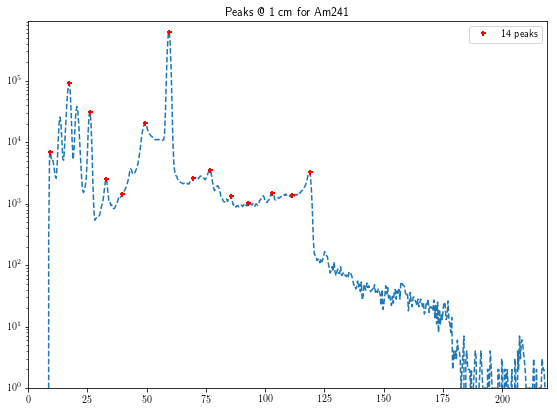

Ba133


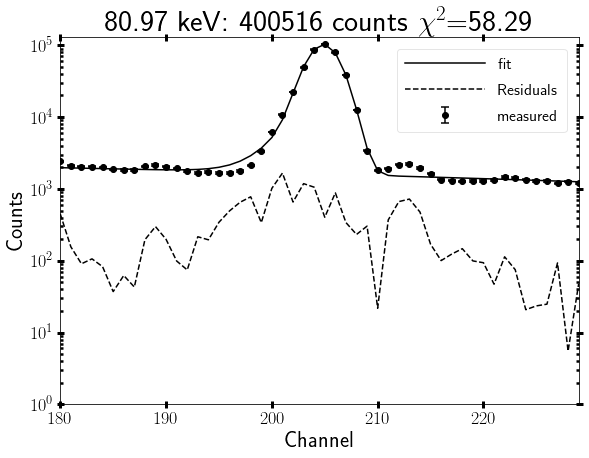

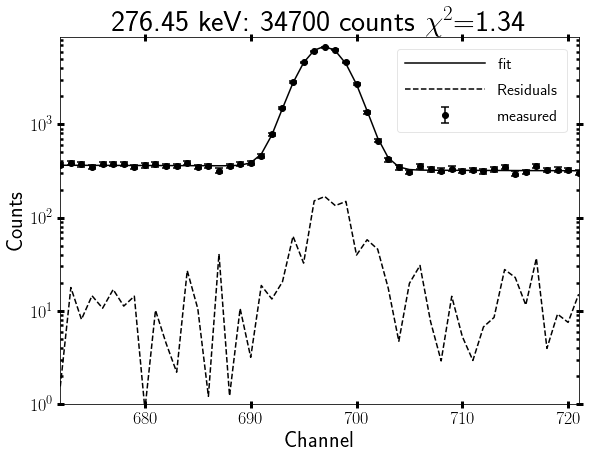

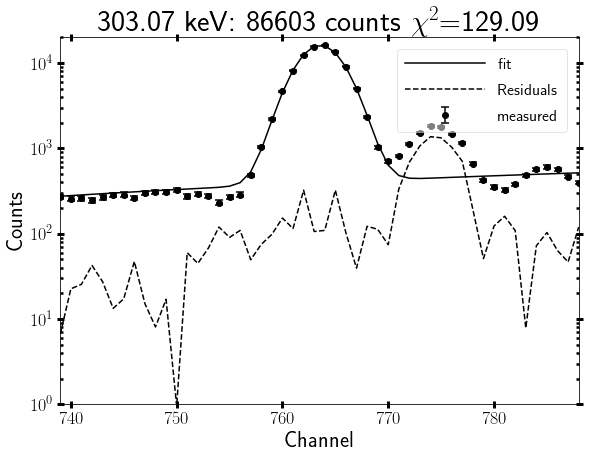

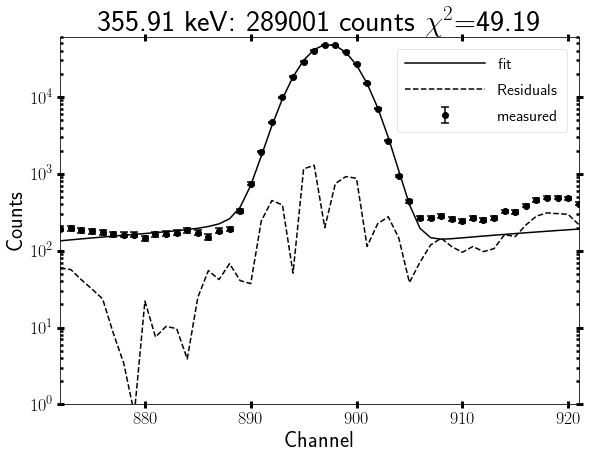


 Ba133
Energy  Peak Area
80.97   400516   632
276.45   34700   186
303.07   86603   294
355.91   289000   537




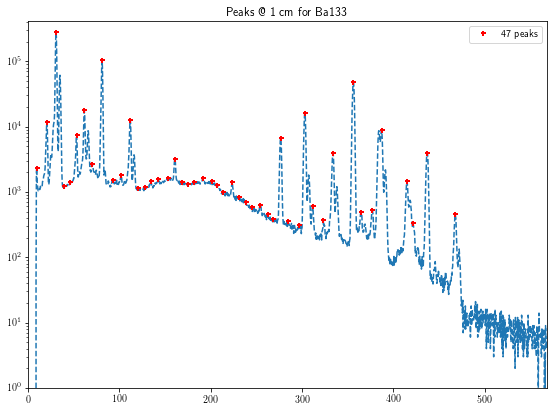

Co60


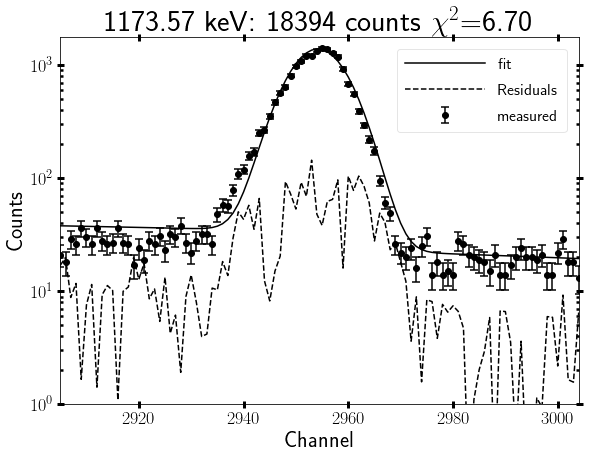

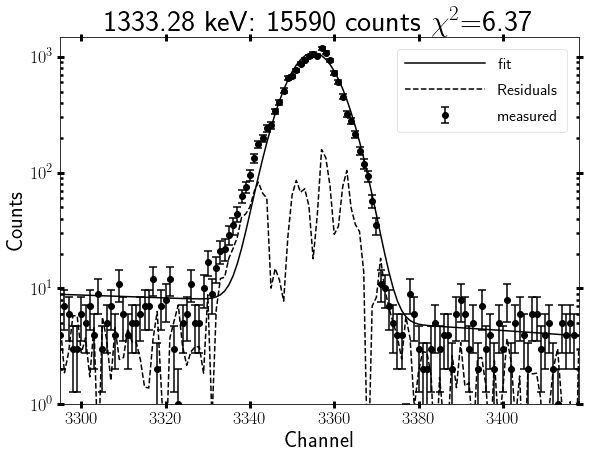


 Co60
Energy  Peak Area
1173.57   18393   135
1333.28   15589   124




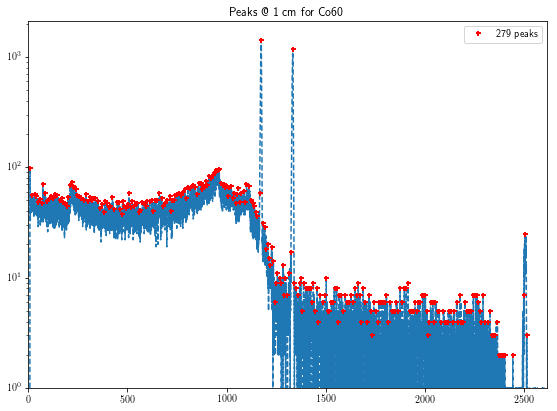

Cs137


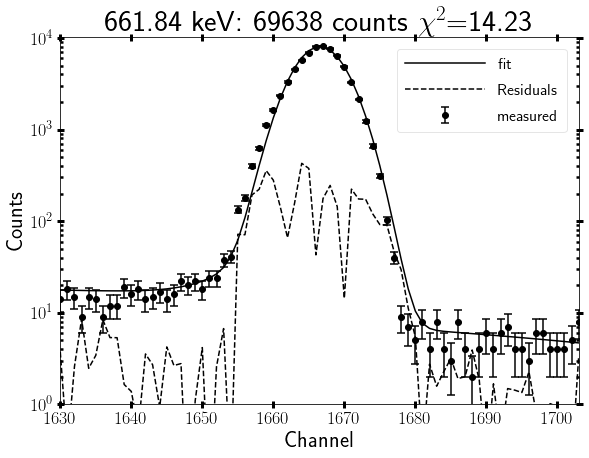


 Cs137
Energy  Peak Area
661.84   69638   263




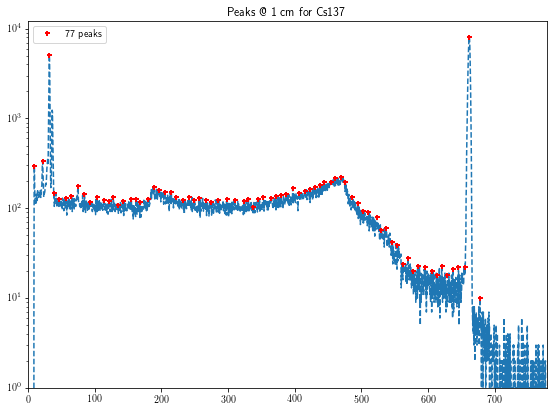

Eu152


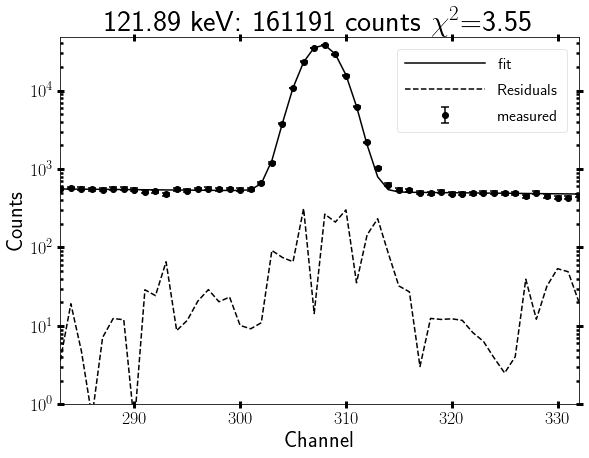

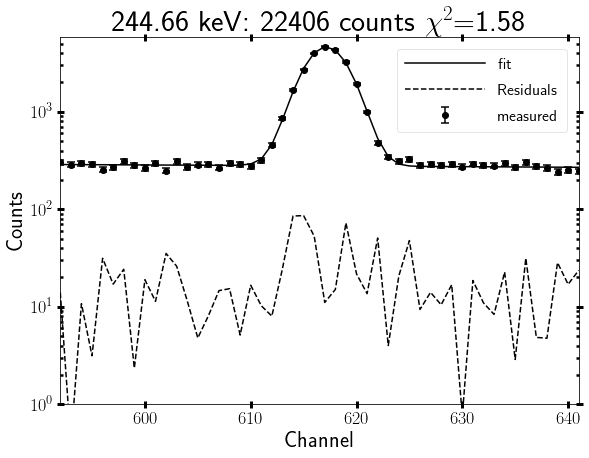

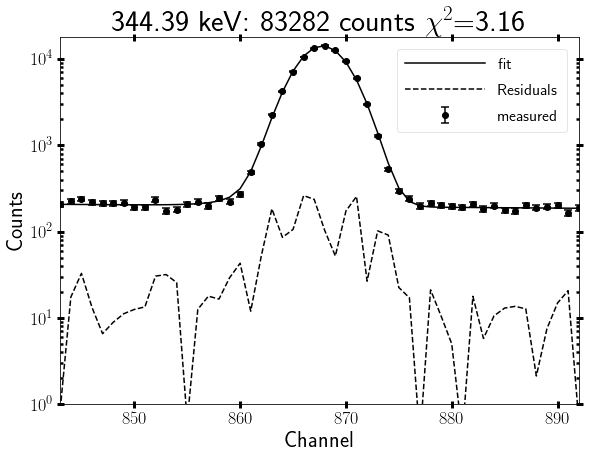

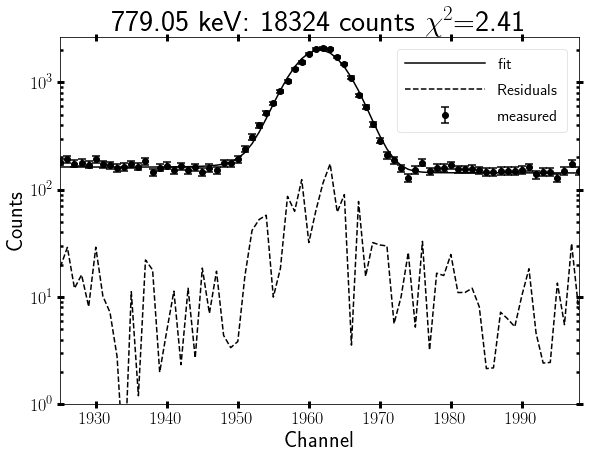

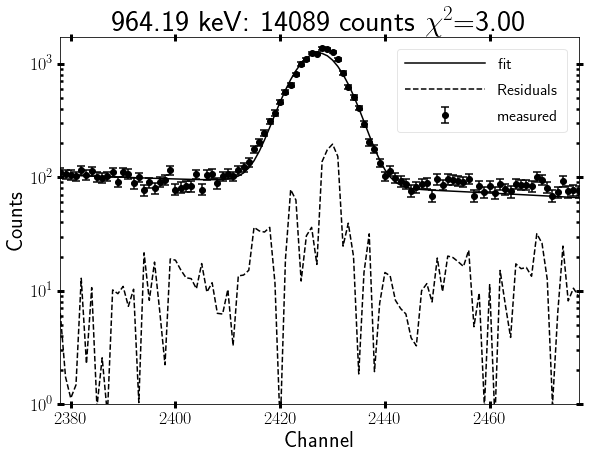

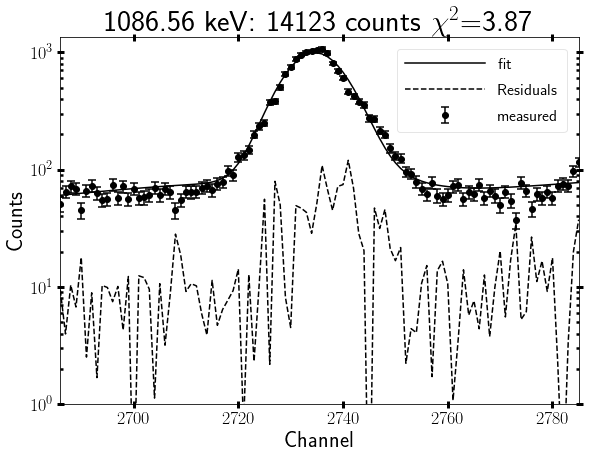

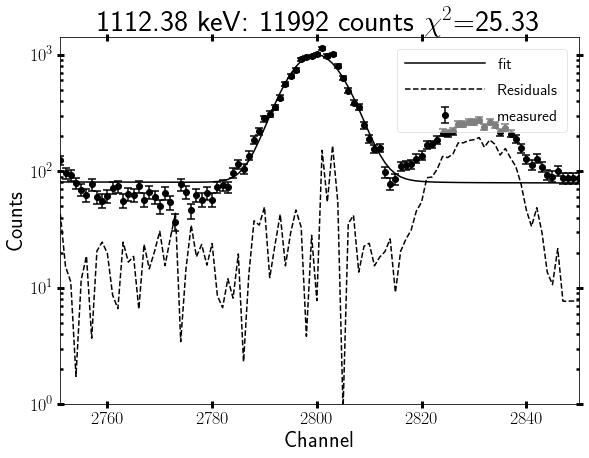

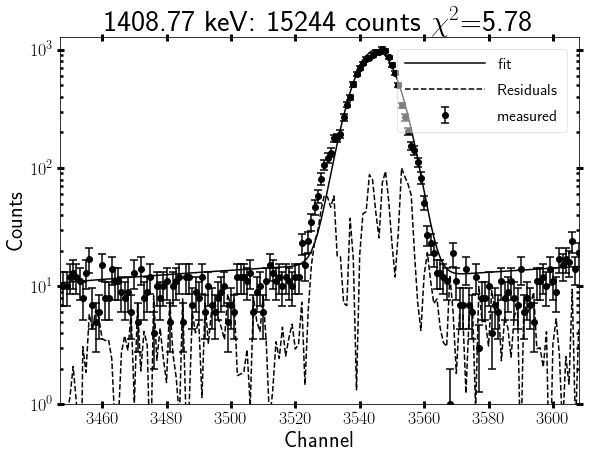


 Eu152
Energy  Peak Area
121.89   161191   401
244.66   22405   149
344.39   83281   288
779.05   18324   135
964.19   14089   118
1086.56   14123   118
1112.38   11992   109
1408.77   15243   123




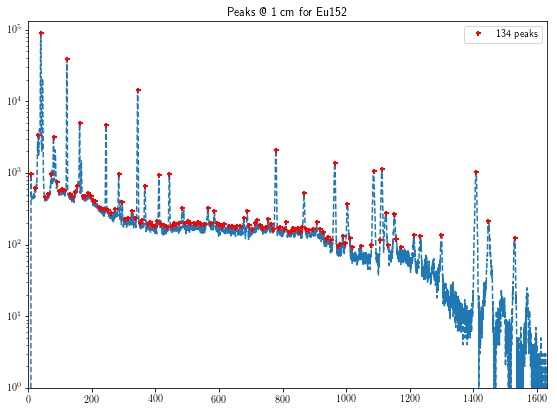

Y88

 Y88
Energy  Peak Area




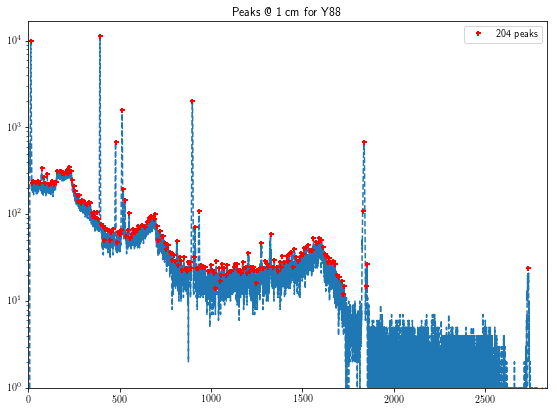

   isotope       line  branchingRatio  measuredCounts  measUncert
0    Am241    59.5409        0.359000         2267197        1505
1    Cs137   661.6570        0.851000           69638         263
2     Co60  1173.2300        0.998500           18393         135
3     Co60  1332.4900        0.999826           15589         124
4    Ba133    80.9979        0.329000          400516         632
5    Ba133   276.4000        0.071600           34700         186
6    Ba133   302.8500        0.183400           86603         294
7    Ba133   356.0100        0.620500          289000         537
8    Eu152   121.7000        0.285300          161191         401
9    Eu152   244.7000        0.075500           22405         149
10   Eu152   344.2900        0.265900           83281         288
11   Eu152   778.9000        0.129300           18324         135
12   Eu152   964.0600        0.145100           14089         118
13   Eu152  1085.8370        0.101100           14123         118
14   Eu152

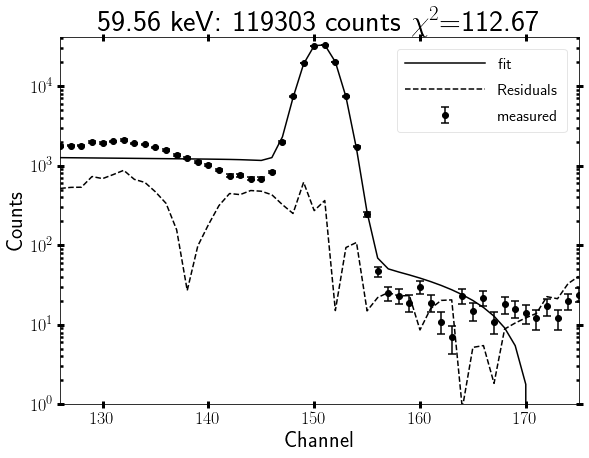


 Am241
Energy  Peak Area
59.56   119303   345




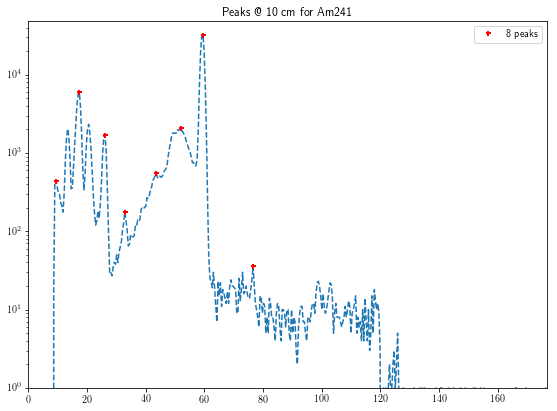

Ba133


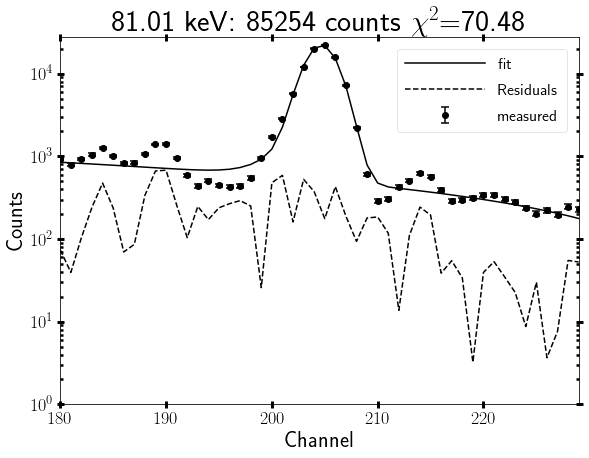

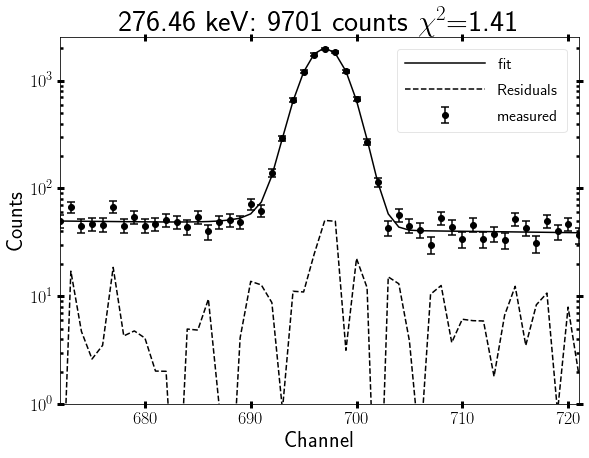

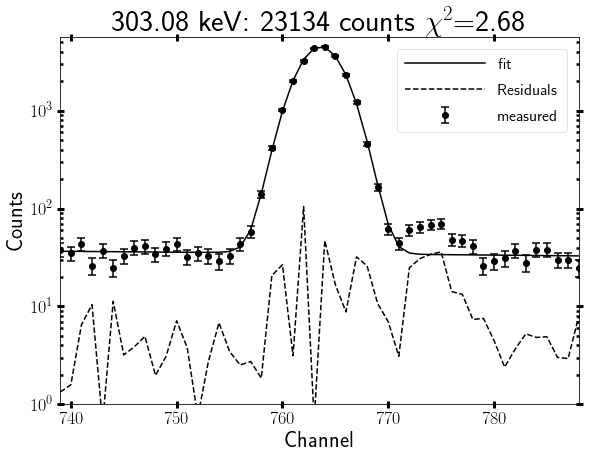

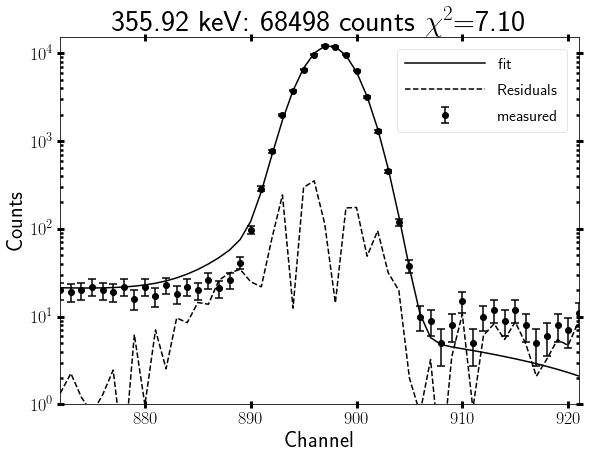


 Ba133
Energy  Peak Area
81.01   85254   291
276.46   9700   98
303.08   23133   152
355.92   68498   261




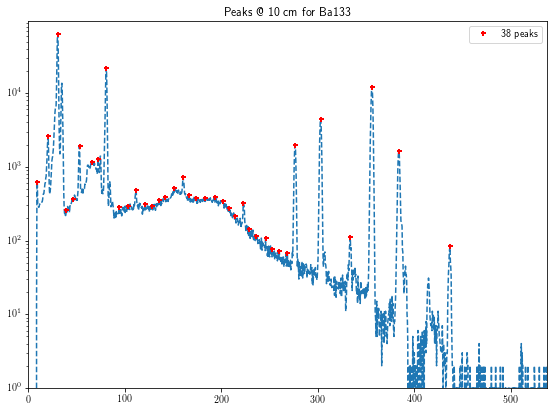

Co60


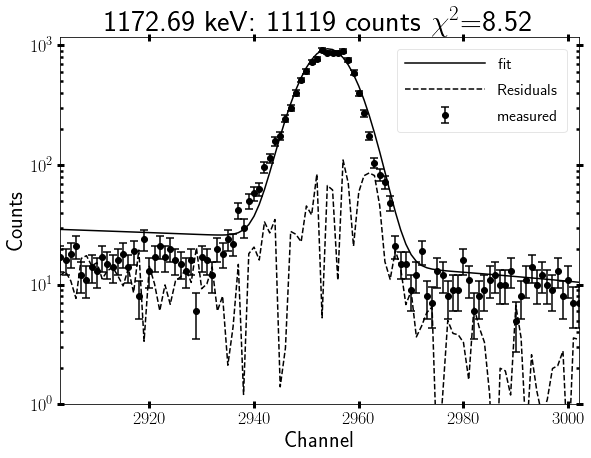

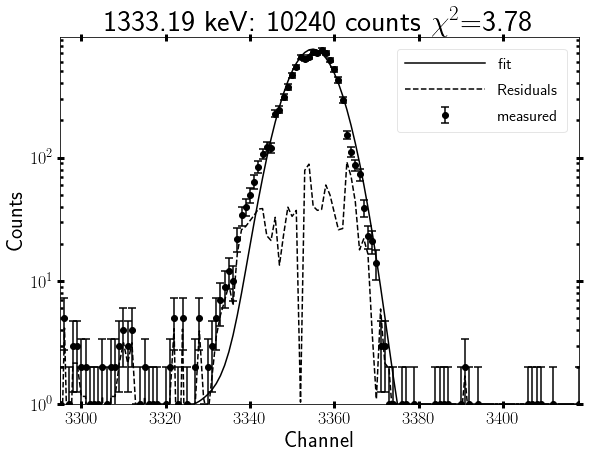


 Co60
Energy  Peak Area
1172.69   11118   105
1333.19   10240   101




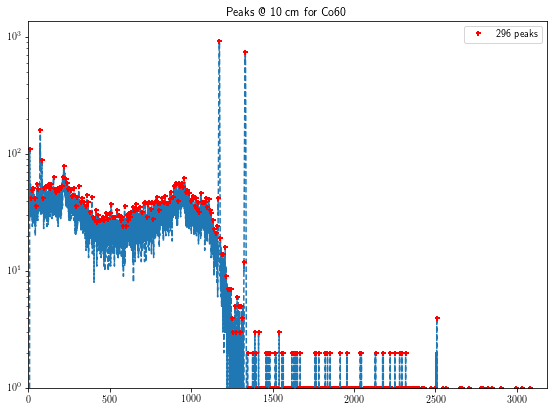

Cs137


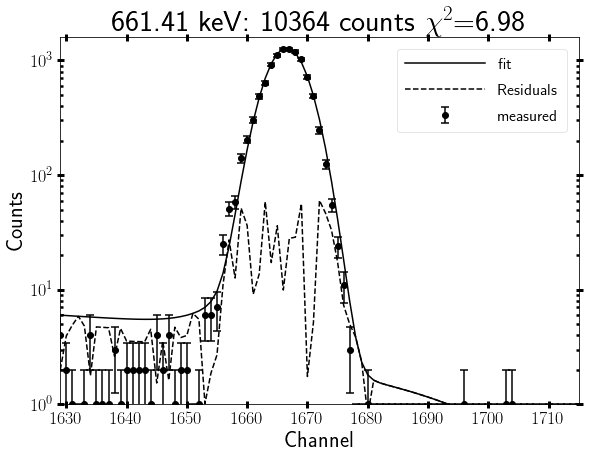


 Cs137
Energy  Peak Area
661.41   10364   101




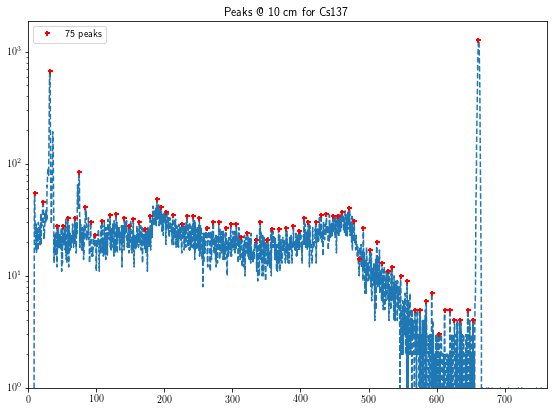

Eu152


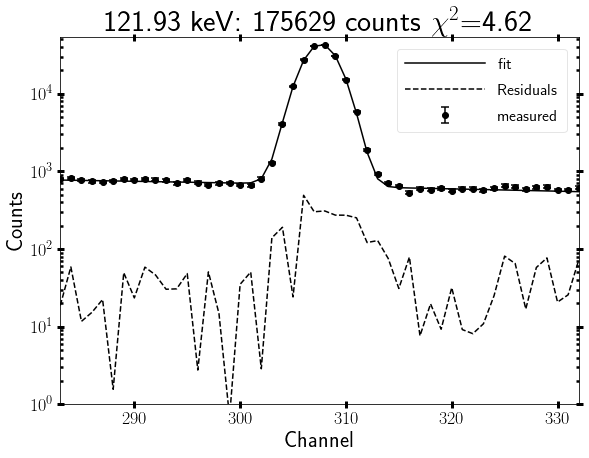

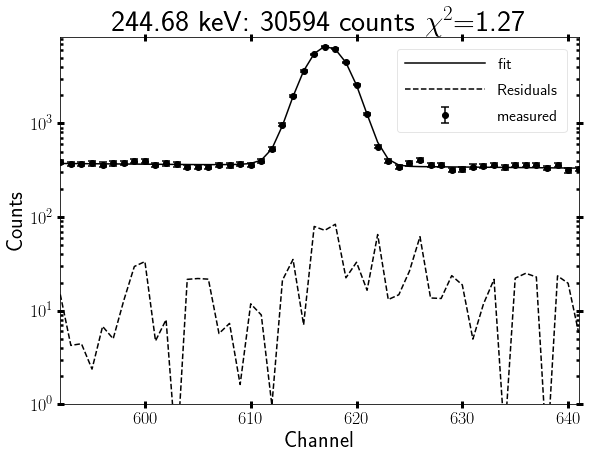

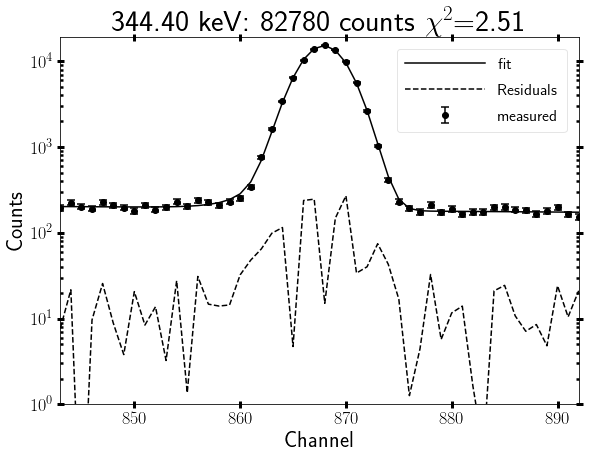

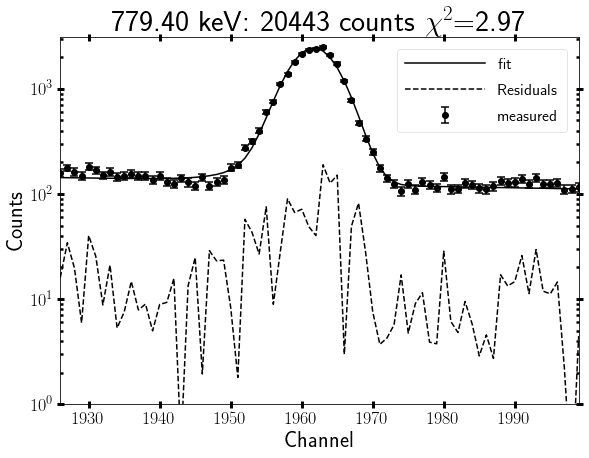

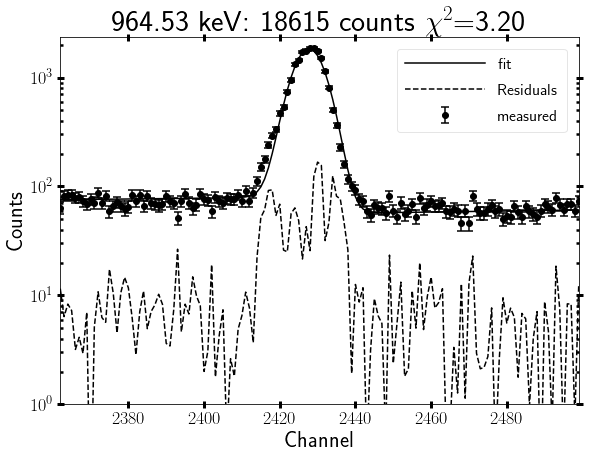

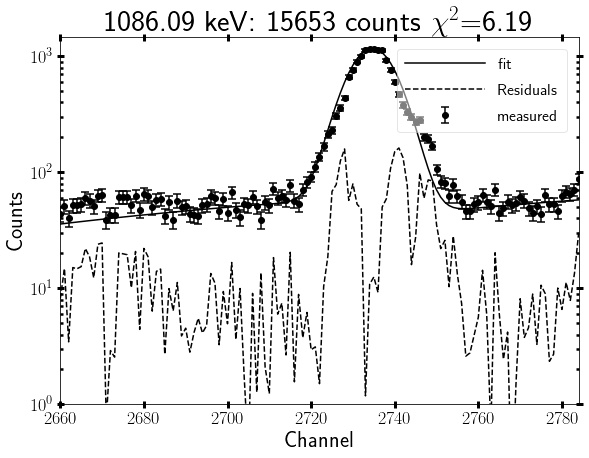

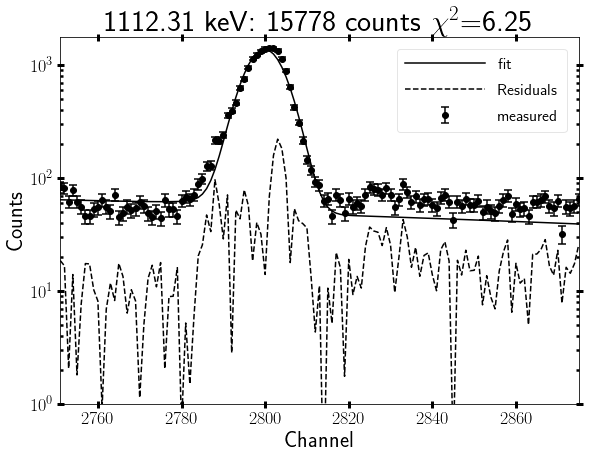

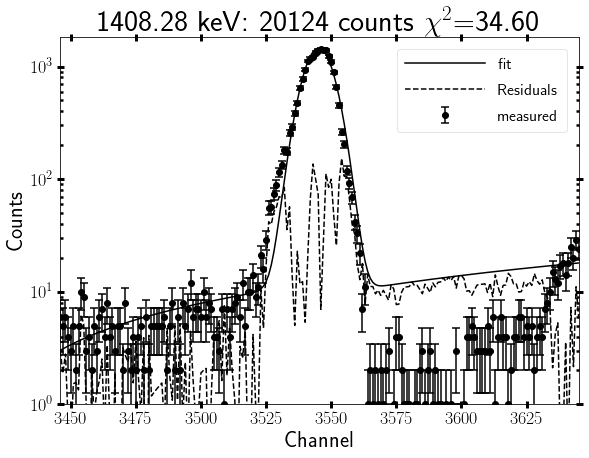


 Eu152
Energy  Peak Area
121.93   175628   419
244.68   30594   174
344.40   82780   287
779.40   20442   142
964.53   18615   136
1086.09   15652   125
1112.31   15778   125
1408.28   20123   141




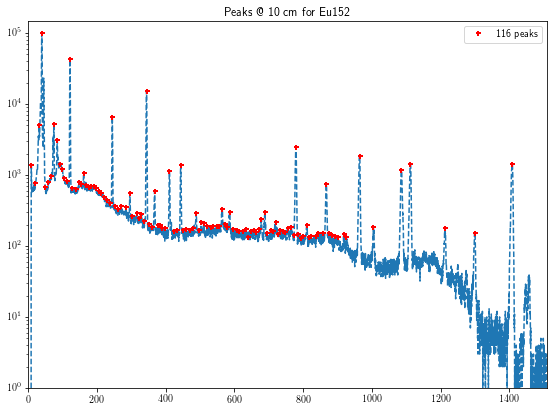

Y88

 Y88
Energy  Peak Area




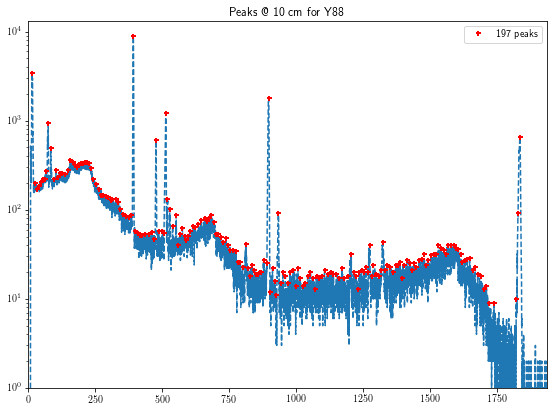

   isotope       line  branchingRatio  measuredCounts  measUncert
0    Am241    59.5409        0.359000          119303         345
1    Cs137   661.6570        0.851000           10364         101
2     Co60  1173.2300        0.998500           11118         105
3     Co60  1332.4900        0.999826           10240         101
4    Ba133    80.9979        0.329000           85254         291
5    Ba133   276.4000        0.071600            9700          98
6    Ba133   302.8500        0.183400           23133         152
7    Ba133   356.0100        0.620500           68498         261
8    Eu152   121.7000        0.285300          175628         419
9    Eu152   244.7000        0.075500           30594         174
10   Eu152   344.2900        0.265900           82780         287
11   Eu152   778.9000        0.129300           20442         142
12   Eu152   964.0600        0.145100           18615         136
13   Eu152  1085.8370        0.101100           15652         125
14   Eu152

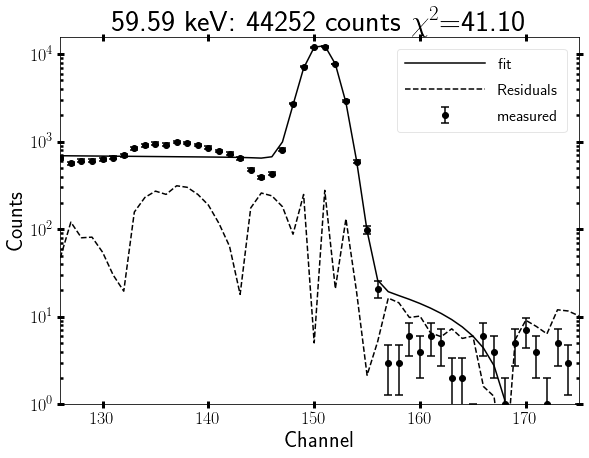


 Am241
Energy  Peak Area
59.59   44251   210




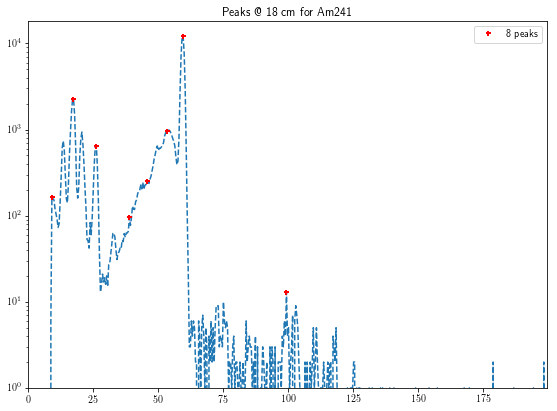

Ba133


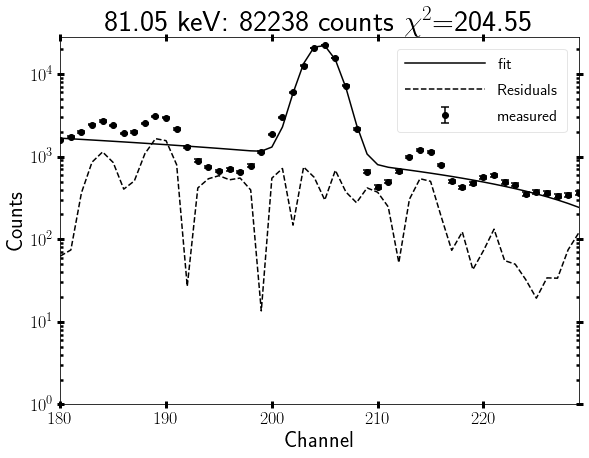

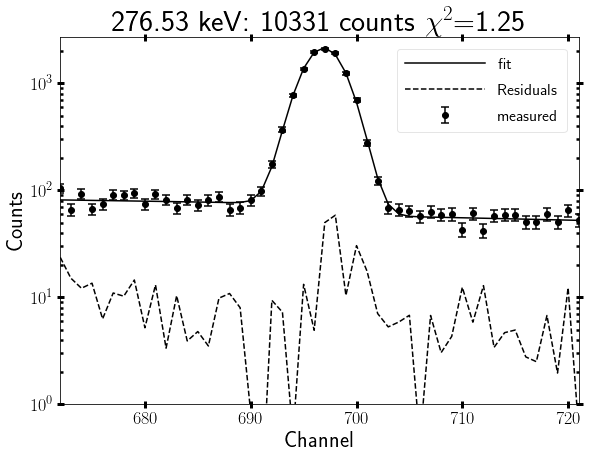

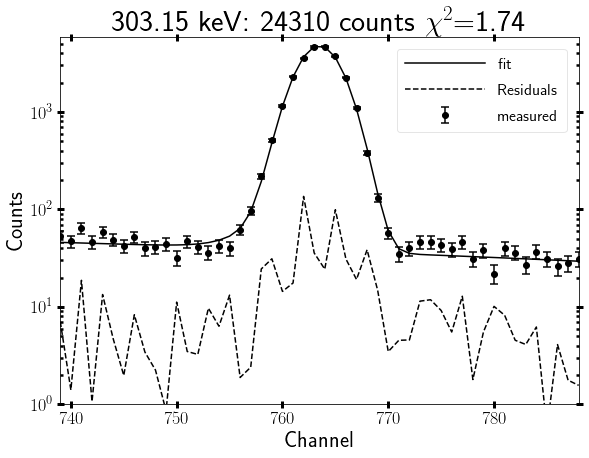

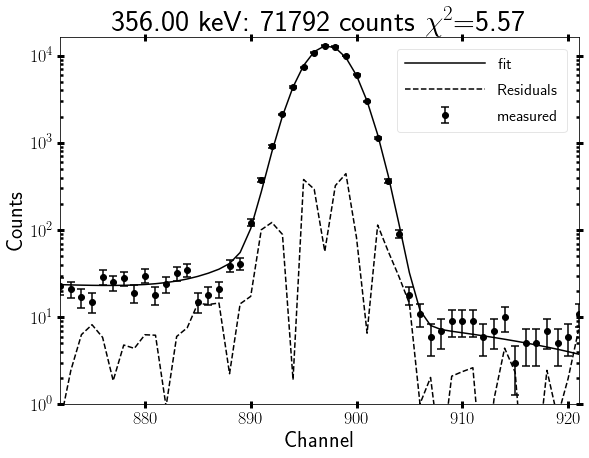


 Ba133
Energy  Peak Area
81.05   82237   286
276.53   10330   101
303.15   24310   155
356.00   71792   267




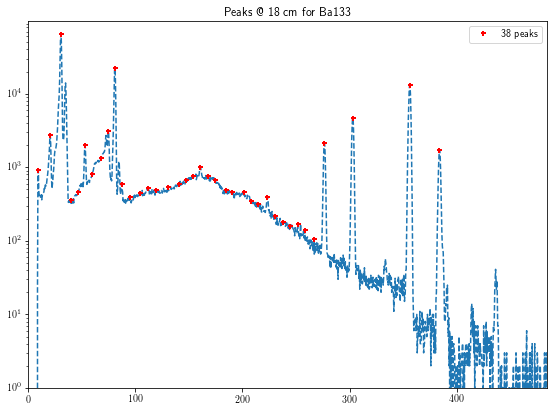

Co60


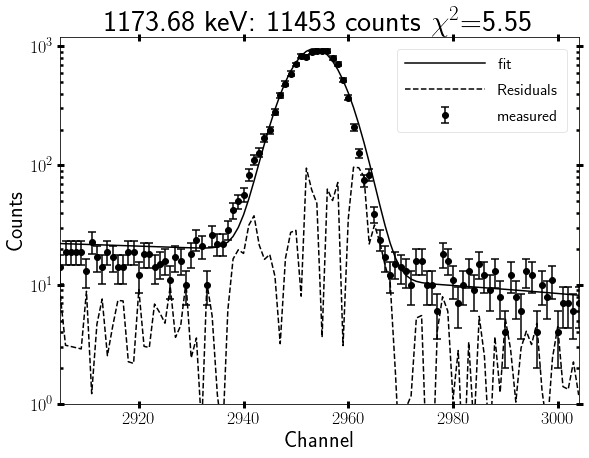

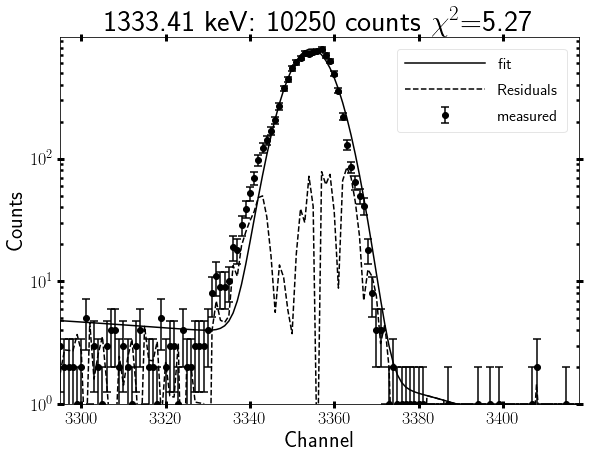


 Co60
Energy  Peak Area
1173.68   11453   107
1333.41   10249   101




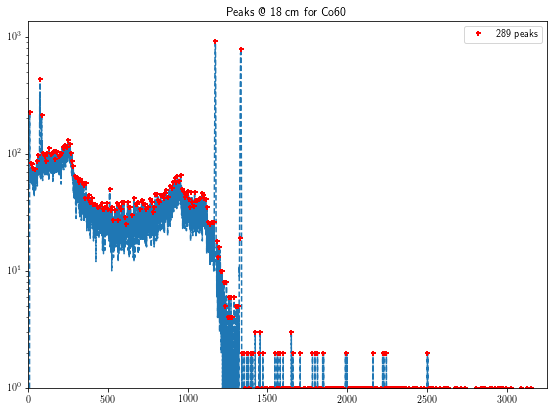

Cs137


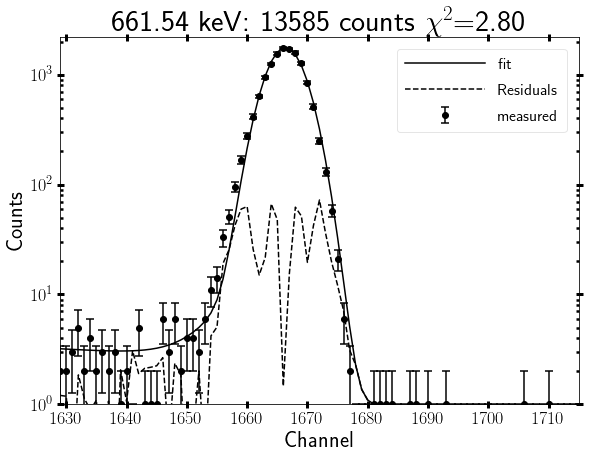


 Cs137
Energy  Peak Area
661.54   13585   116




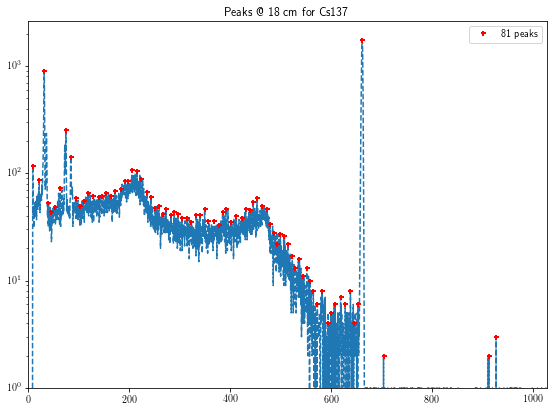

Eu152


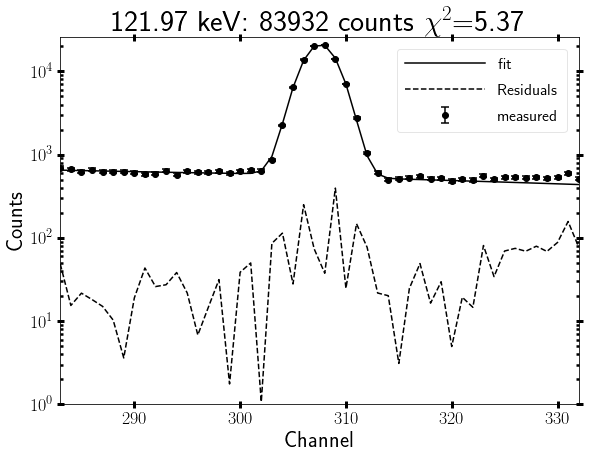

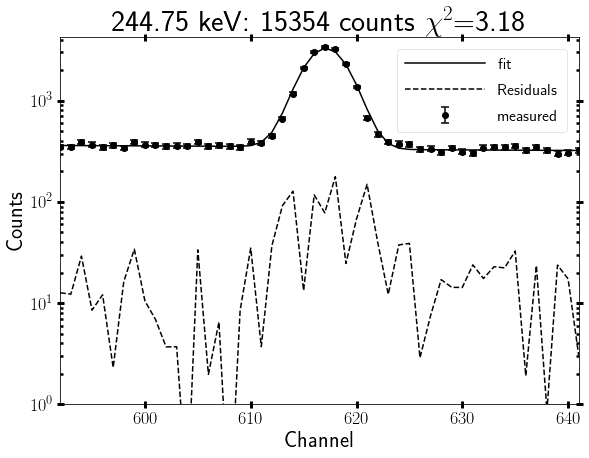

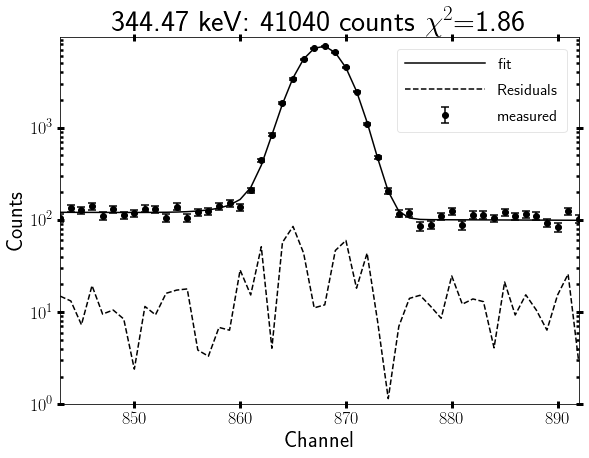

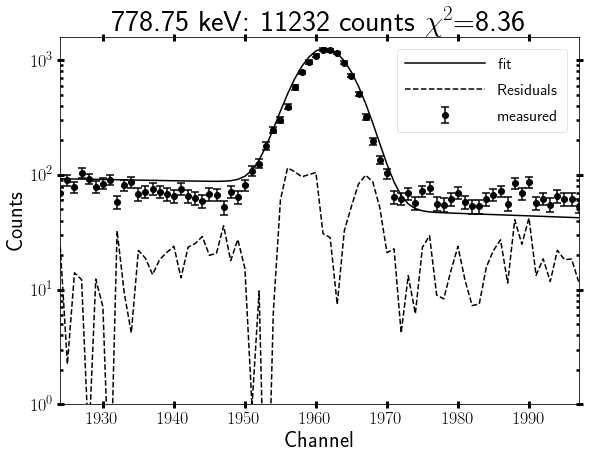

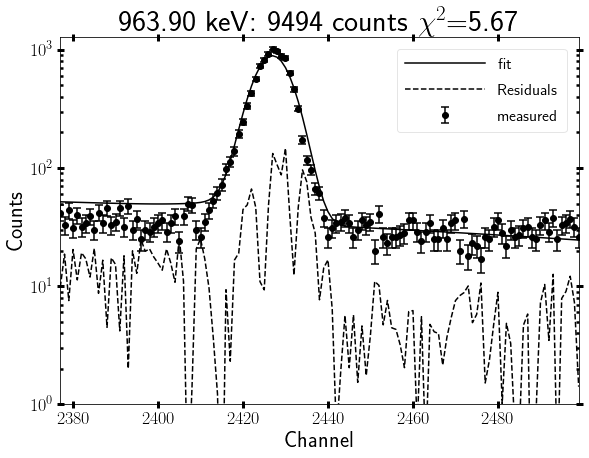

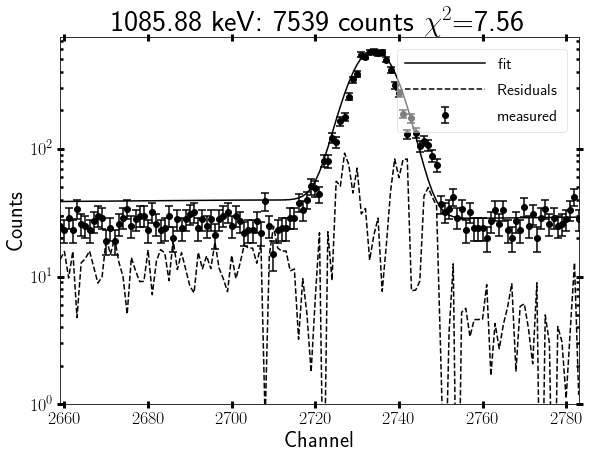

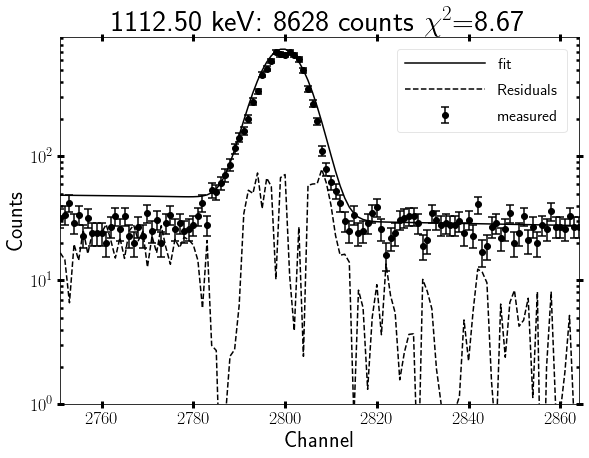

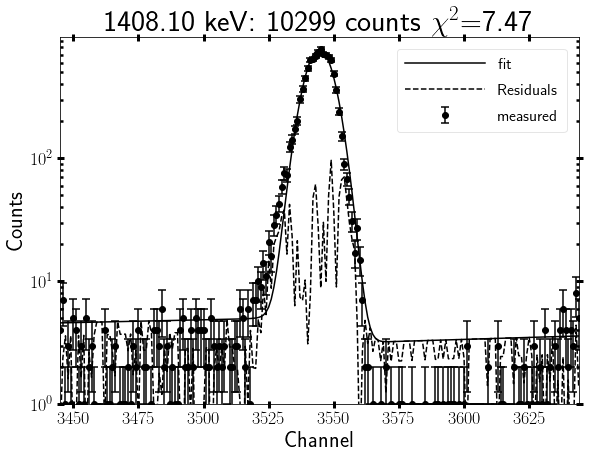


 Eu152
Energy  Peak Area
121.97   83932   289
244.75   15353   123
344.47   41040   202
778.75   11232   105
963.90   9493   97
1085.88   7539   86
1112.50   8627   92
1408.10   10299   101




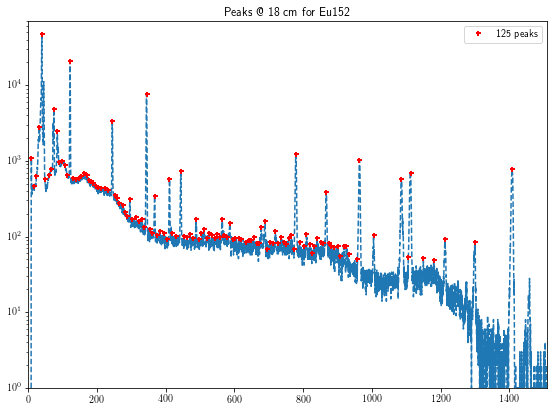

Y88

 Y88
Energy  Peak Area




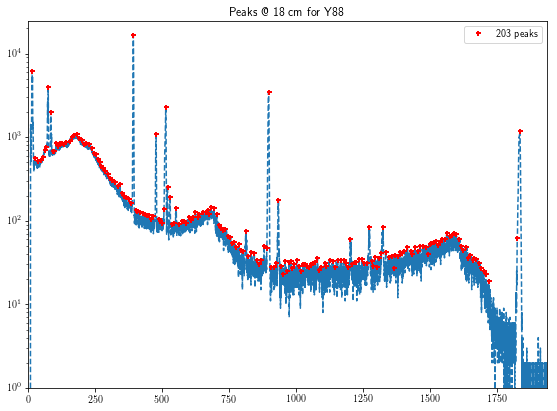

   isotope       line  branchingRatio  measuredCounts  measUncert
0    Am241    59.5409        0.359000           44251         210
1    Cs137   661.6570        0.851000           13585         116
2     Co60  1173.2300        0.998500           11453         107
3     Co60  1332.4900        0.999826           10249         101
4    Ba133    80.9979        0.329000           82237         286
5    Ba133   276.4000        0.071600           10330         101
6    Ba133   302.8500        0.183400           24310         155
7    Ba133   356.0100        0.620500           71792         267
8    Eu152   121.7000        0.285300           83932         289
9    Eu152   244.7000        0.075500           15353         123
10   Eu152   344.2900        0.265900           41040         202
11   Eu152   778.9000        0.129300           11232         105
12   Eu152   964.0600        0.145100            9493          97
13   Eu152  1085.8370        0.101100            7539          86
14   Eu152

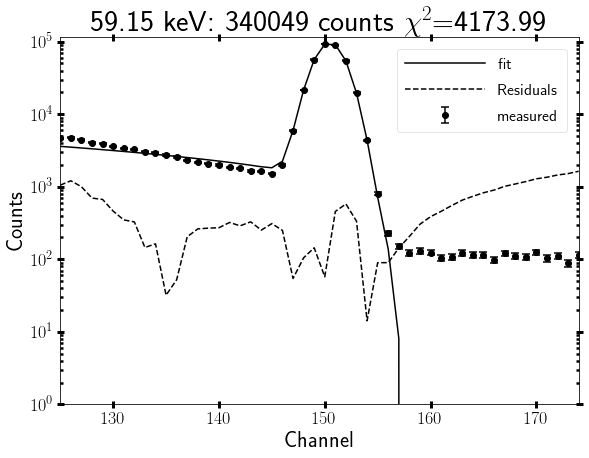


 Am241
Energy  Peak Area
59.15   340049   583




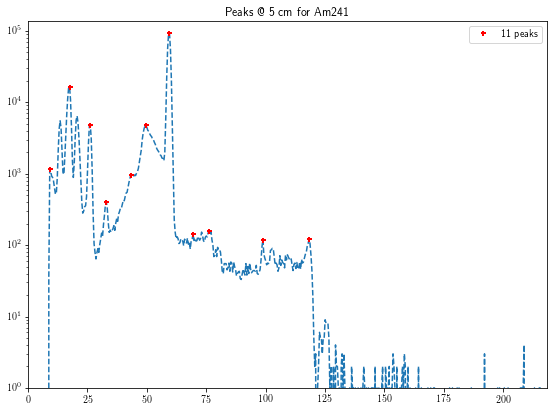

Ba133


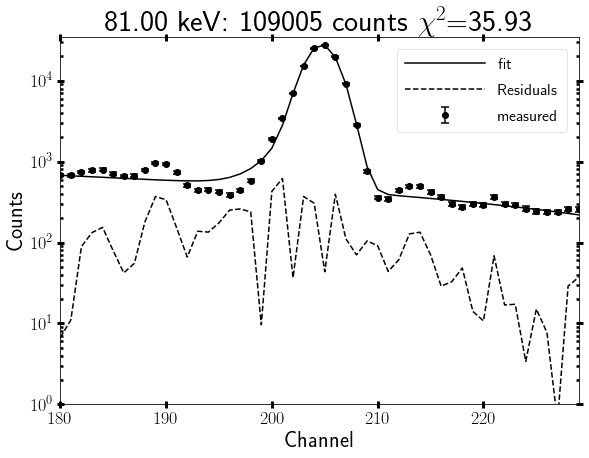

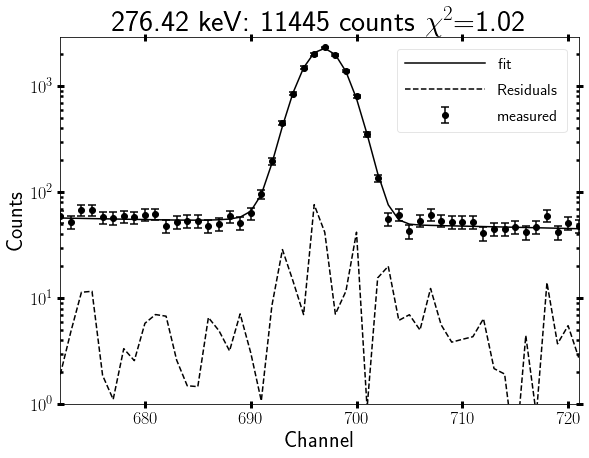

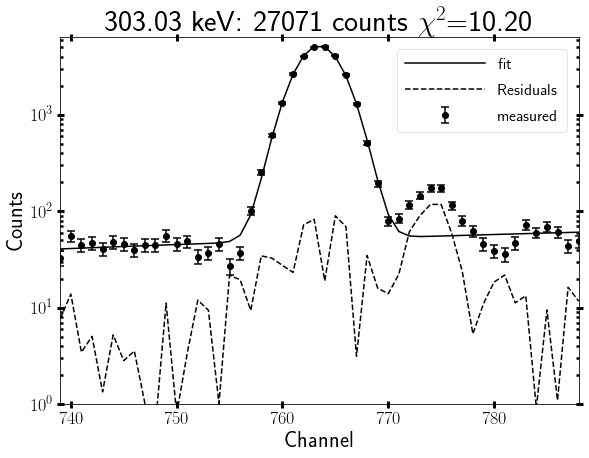

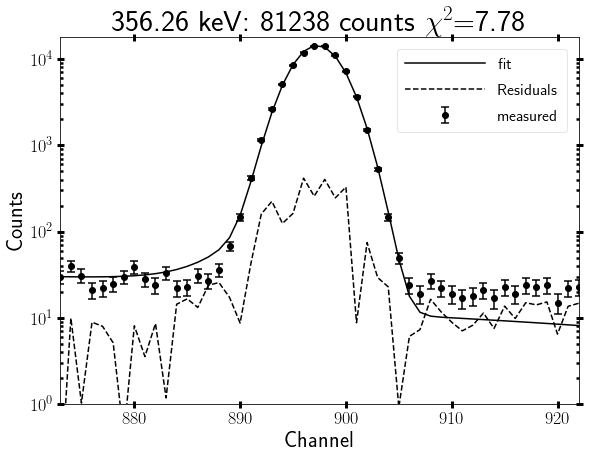


 Ba133
Energy  Peak Area
81.00   109004   330
276.42   11445   106
303.03   27071   164
356.26   81238   285




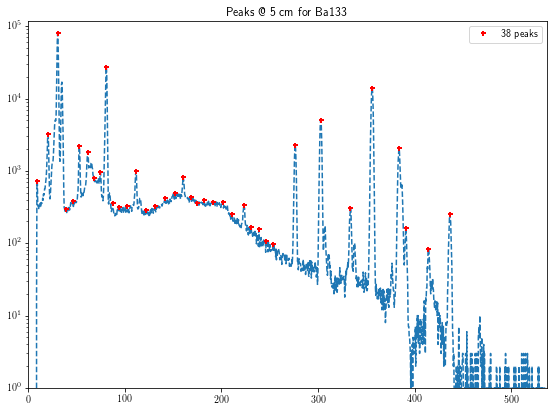

Co60


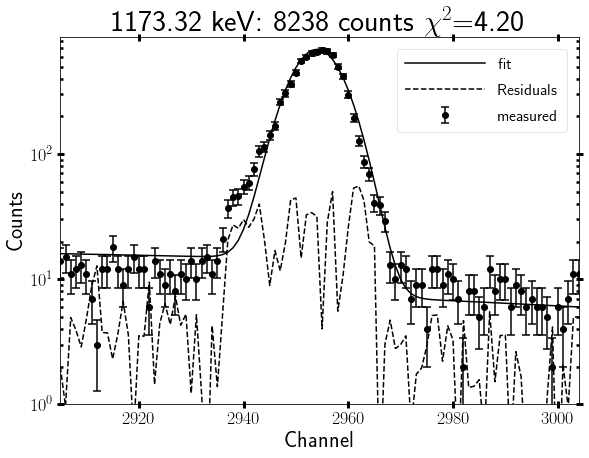

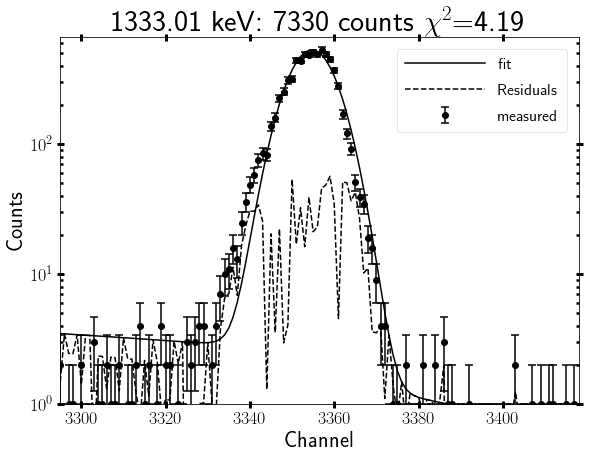


 Co60
Energy  Peak Area
1173.32   8238   90
1333.01   7330   85




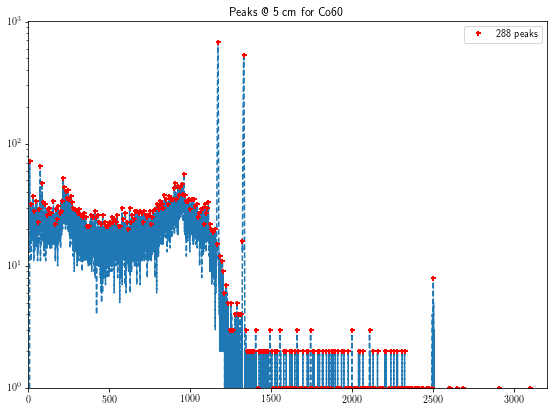

Cs137


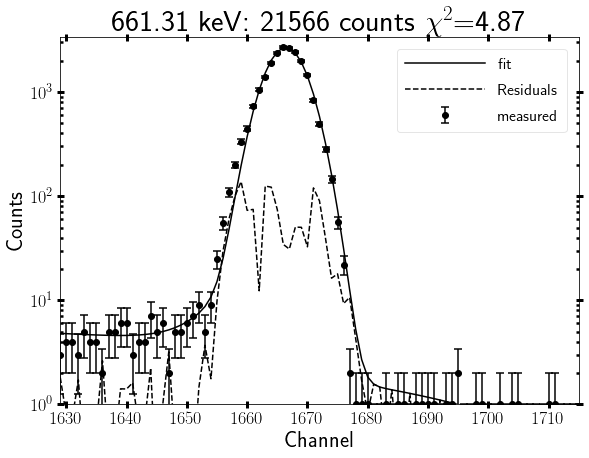


 Cs137
Energy  Peak Area
661.31   21565   146




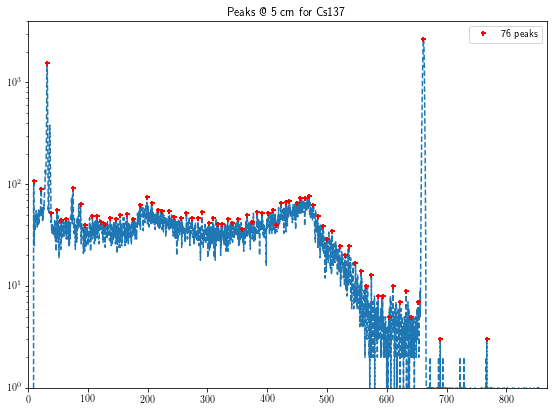

Eu152


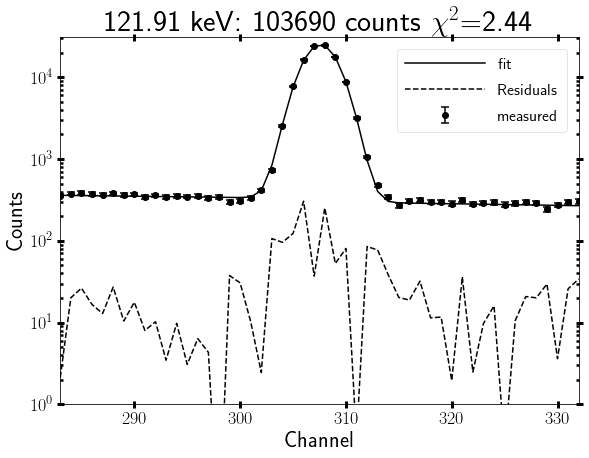

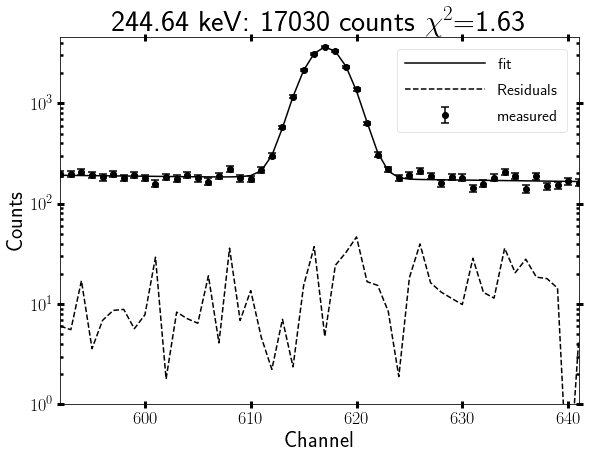

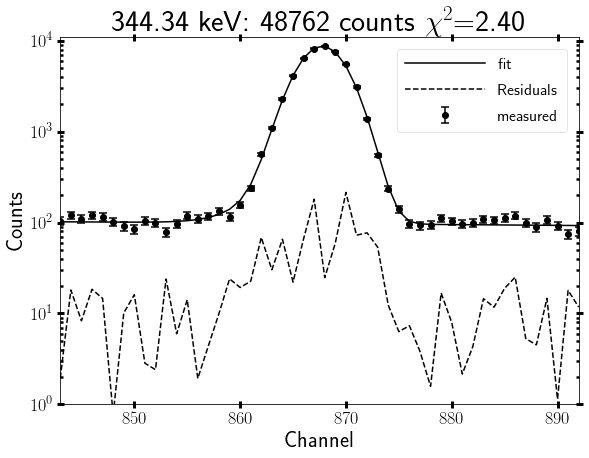

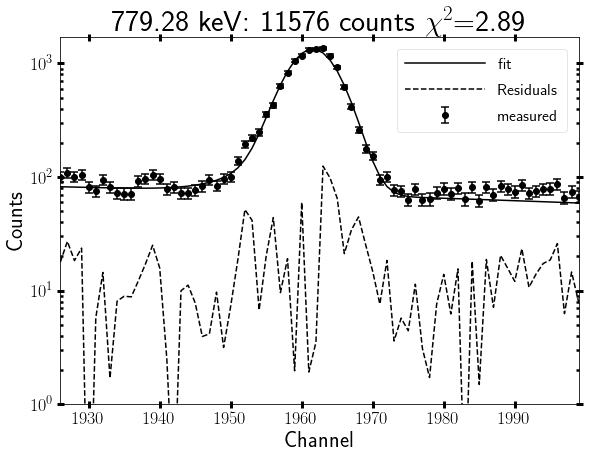

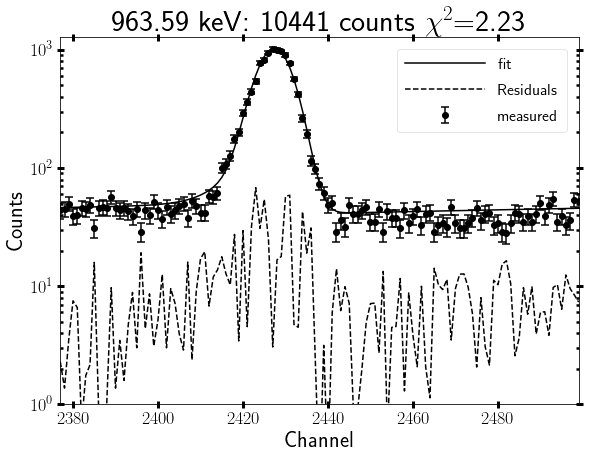

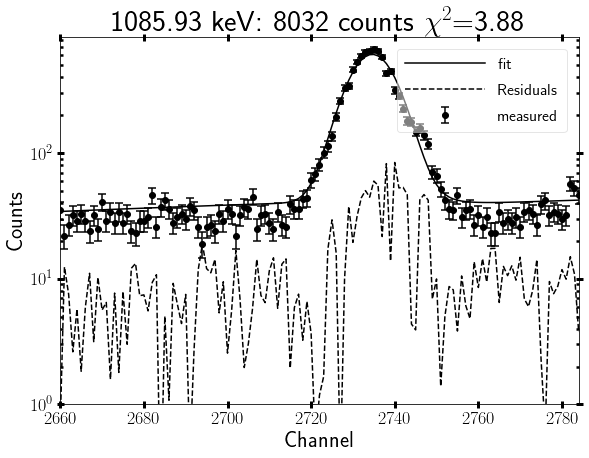

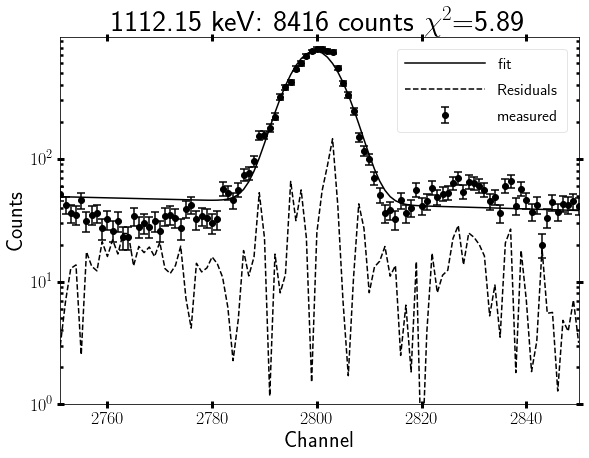

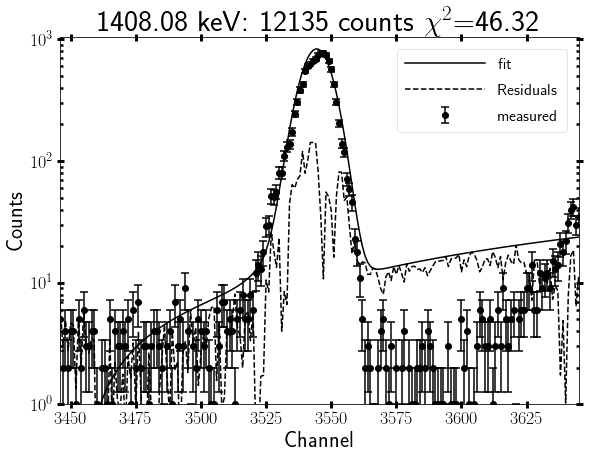


 Eu152
Energy  Peak Area
121.91   103690   322
244.64   17029   130
344.34   48761   220
779.28   11576   107
963.59   10440   102
1085.93   8032   89
1112.15   8415   91
1408.08   12134   110




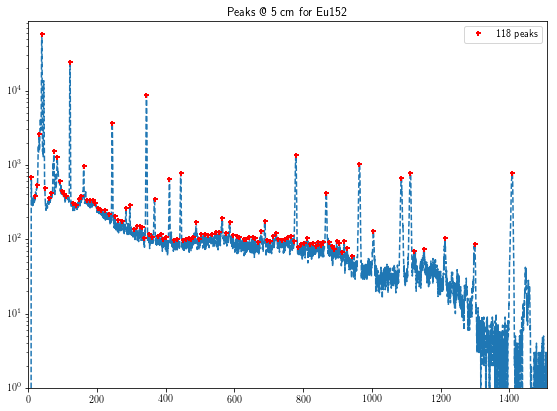

Y88

 Y88
Energy  Peak Area




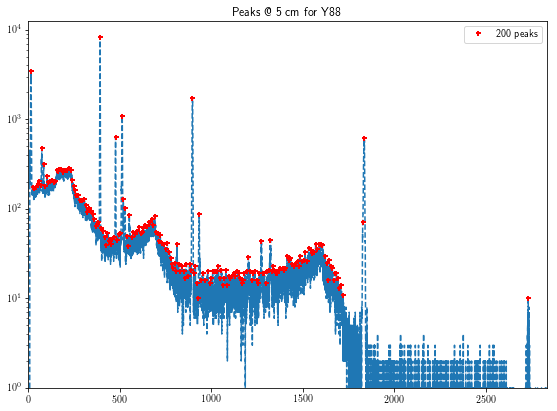

   isotope       line  branchingRatio  measuredCounts  measUncert
0    Am241    59.5409        0.359000          340049         583
1    Cs137   661.6570        0.851000           21565         146
2     Co60  1173.2300        0.998500            8238          90
3     Co60  1332.4900        0.999826            7330          85
4    Ba133    80.9979        0.329000          109004         330
5    Ba133   276.4000        0.071600           11445         106
6    Ba133   302.8500        0.183400           27071         164
7    Ba133   356.0100        0.620500           81238         285
8    Eu152   121.7000        0.285300          103690         322
9    Eu152   244.7000        0.075500           17029         130
10   Eu152   344.2900        0.265900           48761         220
11   Eu152   778.9000        0.129300           11576         107
12   Eu152   964.0600        0.145100           10440         102
13   Eu152  1085.8370        0.101100            8032          89
14   Eu152

In [10]:
# Create a dictionary of data frames to store each of the positional information
peakData = {}
for p in posUsed:
    print "\n------------------------"
    print "Position = {} cm".format(p)
    print "------------------------"
    
    # Update dataframe to store calculated peak information
    lines['measuredCounts'] = 0     
    lines['measUncert'] = 0
    
    for column in data[p]:    
        # Find the peaks and set the windows
        channels = np.asarray(data[p].index)
        counts = np.asarray(data[p][column]).astype(float)
        energy = eCalibParams[p][2]+eCalibParams[p][1]*channels+eCalibParams[p][0]*channels**2
        peaks = peakutils.indexes(counts, thres=0.001, min_dist=15)
        windows = get_peak_windows(peaks, minWindow=25, peakWidth=10, adaptive=True)
        
        # Loop over all identified peaks to compare against calibration points loaded previously
        print data[p][column].name
        output = "\n {}\nEnergy  Peak Area\n".format(data[p][column].name)      
        for i in range(len(lines['line'])):
            for e, pk in zip(energy[peaks], peaks):
                # Calculate the total peak counts if a calibration peak
                if abs(e-lines['line'][i]) < 1.5 and data[p][column].name.strip() == lines['isotope'][i].strip():
                    pkChannels = channels[int(windows[pk][0]):int(windows[pk][1])]
                    pkCounts = counts[windows[pk][0]:windows[pk][1]]
                    (lines.at[i, 'measuredCounts'], lines.at[i, 'measUncert'], redChiSq) = \
                                 ge_peakfit(pkChannels, pkCounts, plotComp=True, plotTitle='{:.2f} keV'.format(e))
                    #pause()    
                    output = output + "{:.2f}   {:.0f}   {:.0f}\n".format(e, lines.at[i, 'measuredCounts'],
                                                                          lines.at[i, 'measUncert'])
            lines.at[i, 'isotope'] = lines.at[i, 'isotope'].strip()
        print output + "\n"
        
        # Plot the peaks found
        fig = pyplot.figure(figsize=(9,6))
        ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.85])
        ax1.set_yscale('log')
        ax1.axis([0, energy[peaks[-1]]+100, 1, max(counts*1.5)])
        pplot(energy, counts, peaks)
        pyplot.title('Peaks @ {} cm for {}'.format(p,data[p][column].name))        
        pyplot.show()
        
    print lines
    peakData[p] = cp.deepcopy(lines)

## Propagation of fitting error?

I started to add this in, but never quite made it.  I was planning on using the theano package to take the partial derivatives of the components of the fitting function, but there are other approaches. This may even be captured in RadWare.

import sys
import os
sys.path.insert(0,os.path.abspath('/home/pyne-user/Dropbox/UCB/Computational_Tools/Scripts/Python/DataAnalysis'))
from Math import gaussScalar
#from sympy import symbols, diff
import theano
#x, a, b, c = symbols('x a b c')
#print diff(gaussScalar(x, a, b, c), x)

### Calculate the current activity

Using the data read in from the .spe files, calculate the current activity at the time of the measurement.  

NOTE:  There is a mix in the activity units.  The initActivity is in $\mu$Ci as reported on the source, whereas the curActivity in is Bq.

In [11]:
sources['curActivity'] = 0

for src in sources.index:
    sources.at[src, 'curActivity'] = decay(sources.at[src, 'halfLife'],sources.at[src, 'initActivity'], \
                                        (sources.at[src, 'measDate']-sources.at[src, 'initDate']).total_seconds())
print sources

        initActivity  initActRelUncert   initDate      halfLife  \
source                                                            
Am241         10.300           0.01165 1970-01-01  1.364420e+10   
Eu152          1.062           0.01165 2009-01-01  4.263262e+08   
Co60           1.007           0.01165 2009-01-01  1.663442e+08   
Cs137          1.042           0.01165 2009-01-01  9.487232e+08   
Ba133          1.078           0.01165 2009-01-01  3.327363e+08   

                   measDate  curActivity  
source                                    
Am241   2017-04-19 11:24:51       353270  
Eu152   2017-04-19 11:40:04        25671  
Co60    2017-04-19 11:29:55        12514  
Cs137   2017-04-19 11:27:40        31841  
Ba133   2017-04-19 11:32:47        23117  


### Calculate absolute efficiency

Determine an absolute efficiency curve for each position by curve fitting the experimental data. The germanium_eff_exp function has support for propogation of error, but the germanium_eff, or germanium_eff_poly are also available.  

NOTE: The choice of which functions to onsider can be set with the functions list.

NOTE: The uncertainty only currently captures the uncertainity in the counts and initial activity.  The uncertaities in BR, half lives, and measurement time are sufficiently small that they can be ignored, but there is uncertainty associated with the fit of the peak that is not captured if germanium_eff_exp is not used.  

The fitting function was: germanium_eff_exp
The curve fitting parameters at 1 cm are: [  1.50724760e-07   2.56221322e+00   5.67691541e-01   6.00509809e-01]
  with standard deviations at 1 cm of: [  2.61371202e-07   2.33548306e-01   2.66658733e-02   9.89633888e-03]

   isotope       line  expectedCounts  absEfficiency  effUncert
0    Am241    59.5409    1.597982e+07       0.141879   0.001653
1    Cs137   661.6570    1.652898e+06       0.042131   0.000491
2     Co60  1173.2300    7.622090e+05       0.024131   0.000281
3     Co60  1332.4900    7.632212e+05       0.020425   0.000238
4    Ba133    80.9979    3.019381e+06       0.132648   0.001545
5    Ba133   276.4000    6.571053e+05       0.052807   0.000615
6    Ba133   302.8500    1.683144e+06       0.051453   0.000599
7    Ba133   356.0100    5.694607e+06       0.050750   0.000591
8    Eu152   121.7000    1.413520e+06       0.114035   0.001329
9    Eu152   244.7000    3.740650e+05       0.059896   0.000698
10   Eu152   344.2900    1.317

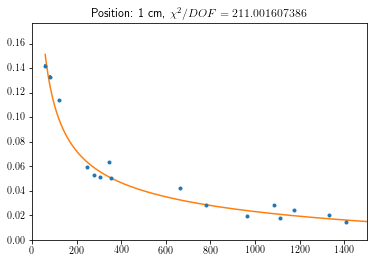

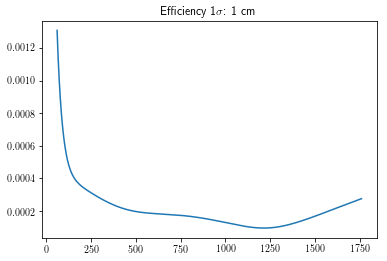

The fitting function was: germanium_eff_exp
The curve fitting parameters at 10 cm are: [  3.15075872e+04  -1.69132416e+00   1.25083014e+00   8.02759227e-01]
  with standard deviations at 10 cm of: [  1.92333020e+04   1.50389884e-01   5.95100322e-02   7.06977729e-03]

   isotope       line  expectedCounts  absEfficiency  effUncert
0    Am241    59.5409    7.736260e+06       0.015421   0.000180
1    Cs137   661.6570    2.357412e+06       0.004396   0.000051
2     Co60  1173.2300    3.985978e+06       0.002789   0.000032
3     Co60  1332.4900    3.991271e+06       0.002566   0.000030
4    Ba133    80.9979    5.164130e+06       0.016509   0.000192
5    Ba133   276.4000    1.123865e+06       0.008631   0.000101
6    Ba133   302.8500    2.878728e+06       0.008036   0.000094
7    Ba133   356.0100    9.739643e+06       0.007033   0.000082
8    Eu152   121.7000    1.218703e+07       0.014411   0.000168
9    Eu152   244.7000    3.225099e+06       0.009486   0.000111
10   Eu152   344.2900    1.1

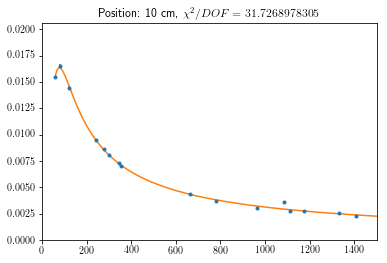

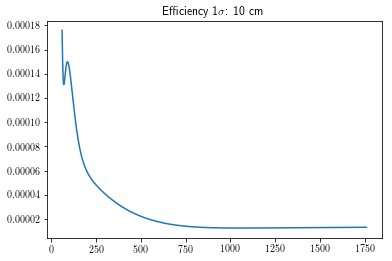

The fitting function was: germanium_eff_exp
The curve fitting parameters at 18 cm are: [  1.33492990e+04  -1.21360851e+00   2.96951409e+00   8.10180316e-01]
  with standard deviations at 18 cm of: [  6.63733165e+03   1.23946250e-01   1.96191101e-01   9.53610467e-03]

   isotope       line  expectedCounts  absEfficiency  effUncert
0    Am241    59.5409    7.736260e+06       0.005720   0.000067
1    Cs137   661.6570    8.101911e+06       0.001677   0.000020
2     Co60  1173.2300    1.059595e+07       0.001081   0.000013
3     Co60  1332.4900    1.061003e+07       0.000966   0.000011
4    Ba133    80.9979    1.393326e+07       0.005902   0.000069
5    Ba133   276.4000    3.032285e+06       0.003407   0.000040
6    Ba133   302.8500    7.767053e+06       0.003130   0.000036
7    Ba133   356.0100    2.627839e+07       0.002732   0.000032
8    Eu152   121.7000    1.549013e+07       0.005418   0.000063
9    Eu152   244.7000    4.099209e+06       0.003745   0.000044
10   Eu152   344.2900    1.4

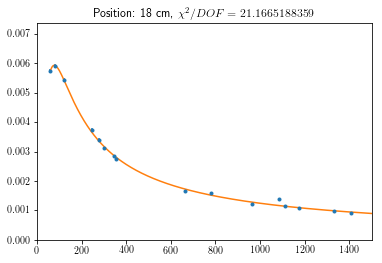

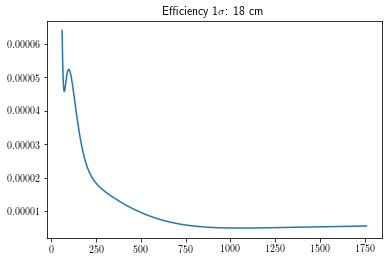

The fitting function was: germanium_eff_exp
The curve fitting parameters at 5 cm are: [  3.65211421e+04  -1.99756742e+00   5.01484137e-01   8.03400416e-01]
  with standard deviations at 5 cm of: [  2.76229065e+04   1.85998071e-01   2.08641247e-02   6.25801268e-03]

   isotope       line  expectedCounts  absEfficiency  effUncert
0    Am241    59.5409    8.116732e+06       0.041895   0.000488
1    Cs137   661.6570    1.869672e+06       0.011534   0.000134
2     Co60  1173.2300    1.174552e+06       0.007014   0.000082
3     Co60  1332.4900    1.176111e+06       0.006232   0.000073
4    Ba133    80.9979    2.448969e+06       0.044510   0.000519
5    Ba133   276.4000    5.329671e+05       0.021474   0.000250
6    Ba133   302.8500    1.365170e+06       0.019830   0.000231
7    Ba133   356.0100    4.618800e+06       0.017589   0.000205
8    Eu152   121.7000    2.753800e+06       0.037653   0.000439
9    Eu152   244.7000    7.287483e+05       0.023367   0.000272
10   Eu152   344.2900    2.566

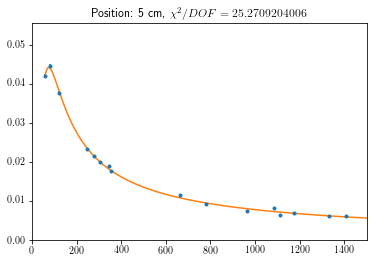

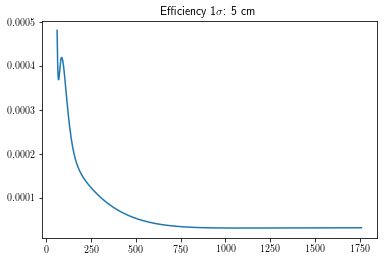

In [12]:
functions=[germanium_eff, germanium_eff_exp]#, germanium_eff_poly]
absEffParams = {}
absEffCov = {}
fitFunc = {} 

for p in posUsed:
    peakData[p]['expectedCounts'] = 0.0
    peakData[p]['absEfficiency'] = 0.0
    peakData[p]['effUncert'] = 0.0
    
    # Calculate the absolute efficiency and uncertainty
    for index, row in peakData[p].iterrows():
        peakData[p].at[index, 'expectedCounts'] = sources.at[peakData[p].at[index, 'isotope'], 'curActivity'] \
                                               * peakData[p].at[index, 'branchingRatio'] \
                                               * liveTime[p][peakData[p].at[index, 'isotope']]
        peakData[p].at[index, 'absEfficiency'] = float(peakData[p].at[index, 'measuredCounts']) \
                                               / float(peakData[p].at[index, 'expectedCounts'])
        peakData[p].at[index, 'effUncert'] = peakData[p].at[index, 'absEfficiency'] * \
                                           sqrt((peakData[p].at[index, 'measUncert'] \
                                           / peakData[p].at[index, 'measuredCounts'])**2 \
                                               + sources.at[peakData[p].at[index, 'isotope'], 'initActRelUncert']**2)
    
    # Fit the data for the current position by finding best fitting routine
    (fitFunc[p], absEffParams[p], absEffCov[p], redChiSq) = find_best_fit(*functions,
                                                     xdata=peakData[p]['line'], ydata=peakData[p]['absEfficiency'],
                                                     sigma=peakData[p]['effUncert'], absolute_sigma=True)
    
    # Output the results
    try:
        print 'The fitting function was: {}'.format(fitFunc[p].__name__)
        print 'The curve fitting parameters at {} cm are: {}'.format(p, absEffParams[p])
        print '  with standard deviations at {} cm of: {}\n'.format(p, np.sqrt(np.diag(absEffCov[p])))
        print peakData[p][['isotope', 'line', 'expectedCounts', 'absEfficiency', 'effUncert']]

        #Plot the Data
        pyplot.axis([0, 1500, 0, 1.25*max(peakData[p]['absEfficiency'])])
        pyplot.errorbar(peakData[p]['line'], peakData[p]['absEfficiency'], peakData[p]['effUncert'], fmt='.')
        pyplot.title('Position: {} cm, $\chi^2/DOF={}$'.format(p, redChiSq))

        #Plot the fit
        xList = np.arange(min(peakData[p]['line']), 1.25*max(peakData[p]['line']), 1)
        yList = map(lambda y: fitFunc[p](y, *absEffParams[p]), xList)
        pyplot.plot(xList, yList)
        pyplot.show()

        #Plot the error
        if fitFunc[p] == germanium_eff_exp:
            pyplot.title('Efficiency 1$\sigma$: {} cm'.format(p))
            xList = np.arange(min(peakData[1]['line']), 1.25*max(peakData[1]['line']), 1)
            yList = map(lambda y: curve_fit_error4(fitFunc[p], np.insert(absEffParams[p], 0, y), y*0.001, 
                                                   absEffCov[p]), xList)
            pyplot.plot(xList, yList)
            pyplot.show()
    except AttributeError:
        print 'No fit was found'
        print peakData[p][['isotope', 'line', 'expectedCounts', 'absEfficiency', 'effUncert']]
        
        #Plot the Data
        pyplot.axis([0, 1500, 0, 1.25*max(peakData[p]['absEfficiency'])])
        pyplot.errorbar(peakData[p]['line'], peakData[p]['absEfficiency'], peakData[p]['effUncert'], fmt='.')
        pyplot.title('Position: {} cm, $\chi^2/DOF={}$'.format(p, redChiSq))
        pyplot.show()

## Count Plan

Develop a count plan based on the planned irradiation. This assumes that you have a priori abs effeciency calibration parameters for the position of interest. 

### Cave01 Normalization Activation Foils

#### Experimental parameters

Specifies experimental parameters for the beam and counting facility used.

runTime = the beam irradiation time in s

transitTime = the minimum time to counting of the first foil in s

background = the background rate at the peak of interest in counts/s

detR = radius of the detector in cm

In [13]:
runTime = 900
transitTime = 600

background = 0.01
detR = 3.245

#### Read in Simulation data

Read from the designated file path.  Manipulate the file to build a dataframe with the information needed for the count plan.  

In [14]:
simVaultFoils = pd.read_excel(simFoilPath, sheetname='BeamBox')

# Delete unneccesary columns for readability and make the index the reactant
simVaultFoils.index = simVaultFoils.Rx
del simVaultFoils['Rx']
del simVaultFoils['Thickness [cm]']
del simVaultFoils['Density']
del simVaultFoils['AW']
del simVaultFoils['Lambda [s^-1]']

# Rename columns for ease of access and add in the statistics column
simVaultFoils.columns = ['foil', 'product', 'gammaEnergy', 'br', 'relStat', 'det2FoilDist', 'normalization', 'rxRate',
                         'rxRateSigma', 'foilR','weightFrac', 'volume', 'halfLife']

# Put branching ratios in fractional form
simVaultFoils['br'] = simVaultFoils['br']/100.

# Calculate the activity following transit time decay for each rx; delete columns no longer needed
simVaultFoils['initActivity'] = 0.0
simVaultFoils['activityUncert'] = 0.0
for ind in simVaultFoils.index:
    simVaultFoils.at[ind,'initActivity'] = production_decay(simVaultFoils.at[ind, 'halfLife'], 0, runTime, \
                                                    simVaultFoils.at[ind, 'rxRate'], \
                                                    simVaultFoils.at[ind, 'normalization'], \
                                                    simVaultFoils.at[ind, 'volume'], transitTime)\
                                                    *get_decay_const(simVaultFoils.at[ind,'halfLife'])\
                                                    *simVaultFoils.at[ind,'br']
    simVaultFoils.at[ind,'activityUncert'] = simVaultFoils.at[ind, 'initActivity']*simVaultFoils.at[ind, 'rxRateSigma']
del simVaultFoils['rxRate']
del simVaultFoils['normalization']
del simVaultFoils['volume']
del simVaultFoils['rxRateSigma']

print simVaultFoils

                foil product  gammaEnergy      br  relStat  det2FoilDist  \
Rx                                                                         
27Al(n,p)b18   Alb18    Mg27      843.760  0.7180     0.01            18   
27Al(n,p)a18   Ala18    Mg27      843.760  0.7180     0.01            18   
27Al(n,a)a18   Ala18    Na24     1368.630  0.9999     0.01            18   
27Al(n,p)b5     Alb5    Mg27      843.760  0.7180     0.01             5   
27Al(n,p)b       Alb    Mg27      843.760  0.7180     0.01             1   
27Al(n,p)a       Ala    Mg27      843.760  0.7180     0.01             1   
27Al(n,a)a       Ala    Na24     1368.630  0.9999     0.01             1   
115In(n,n')18   In18  In115M      336.241  0.4580     0.01            18   
115In(n,g)18    In18  In116M     1293.560  0.8480     0.01            18   
115In(n,n')       In  In115M      336.241  0.4580     0.01             1   
115In(n,g)        In  In116M     1293.560  0.8480     0.01             1   
197Au(n,2n)1

In [15]:
(simVaultFoils, countTime) = count_plan(simVaultFoils, handleTime=75, detR=detR, background=background, 
                                                    units='Bq', toMinute = True, 
                                                    funcDict=fitFunc, funcParamDict=absEffParams )
    
#(simVaultFoils,countOrder,countTime) = optimal_count_plan(simVaultFoils, handleTime=75, detR=detR, background=background, 
#                                                    units='Bq', toMinute = True, 
#                                                    funcDict=fitFunc, funcParamDict=absEffParams )

#print 'The order of counting is: {}\n'.format(countOrder)
print 'Total count time = {:2e} hrs\n'.format(countTime/60)
for ind in simVaultFoils.index:
    print "{:15s} {:4.0f} min".format(ind, simVaultFoils.at[ind,"countTime"])

Total count time = 1.951667e+01 hrs

27Al(n,p)b18       1 min
27Al(n,p)a18       1 min
27Al(n,a)a18       1 min
27Al(n,p)b5        1 min
27Al(n,p)b         1 min
27Al(n,p)a         1 min
27Al(n,a)a         1 min
115In(n,n')18      1 min
115In(n,g)18       1 min
115In(n,n')        1 min
115In(n,g)         1 min
197Au(n,2n)18    549 min
197Au(n,g)18     549 min
197Au(n,2n)       26 min
197Au(n,g)        26 min
58Ni(n,2n)18       3 min
58Ni(n,p)18        3 min
58Ni(n,2n)         1 min
58Ni(n,p)          1 min
90Zr(n,2n)18       1 min
90Zr(n,2n)         1 min


### Cave Activation Foils

#### Experimental Parameters

In [16]:
runTime = 3600*2
transitTime = 360

background = 0.01
detR = 3.245

#### Read in Simulation data

Read from the designated file path.  Manipulate the file to build a dataframe with the information needed for the count plan.  

In [17]:
simCaveFoils = pd.read_excel(simFoilPath, sheetname='Cave')

# Delete unneccesary columns for readability and make the index the reactant
simCaveFoils.index = simCaveFoils.Rx
del simCaveFoils['Rx']
del simCaveFoils['Thickness [cm]']
del simCaveFoils['Density']
del simCaveFoils['AW']
del simCaveFoils['Lambda [s^-1]']

# Rename columns for ease of access and add in the statistics column
simCaveFoils.columns = ['foil', 'product', 'gammaEnergy', 'br', 'relStat', 'det2FoilDist', 'normalization', 'rxRate',
                         'rxRateSigma', 'foilR','weightFrac', 'volume', 'halfLife']

# Put branching ratios in fractional form
simCaveFoils['br'] = simCaveFoils['br']/100.

# Calculate the activity following transit time decay for each rx; delete columns no longer needed
simCaveFoils['initActivity'] = 0.0
simCaveFoils['activityUncert'] = 0.0
for ind in simCaveFoils.index:
    simCaveFoils.at[ind,'initActivity'] = production_decay(simCaveFoils.at[ind, 'halfLife'], 0, runTime, \
                                                    simCaveFoils.at[ind, 'rxRate'], \
                                                    simCaveFoils.at[ind, 'normalization'], \
                                                    simCaveFoils.at[ind, 'volume'], transitTime)\
                                                    *get_decay_const(simCaveFoils.at[ind,'halfLife'])\
                                                    *simCaveFoils.at[ind,'br']
    simCaveFoils.at[ind,'activityUncert'] = simCaveFoils.at[ind, 'initActivity']*simCaveFoils.at[ind, 'rxRateSigma']
del simCaveFoils['rxRate']
del simCaveFoils['normalization']
del simCaveFoils['volume']
del simCaveFoils['rxRateSigma']

print simCaveFoils

            foil product  gammaEnergy      br  relStat  det2FoilDist  foilR  \
Rx                                                                            
27Al(n,p)     Al    Mg27      843.760  0.7180     0.01             1    2.5   
27Al(n,a)     Al    Na24     1368.630  0.9999     0.01             1    2.5   
115In(n,n')   In  In115M      336.241  0.4580     0.01             1    2.5   
115In(n,g)    In  In116M     1293.560  0.8480     0.01             1    2.5   
197Au(n,2n)   Au   Au196      355.700  0.8090     0.01             1    2.5   
58Ni(n,2n)    Ni    Ni57     1377.630  0.8170     0.01             1    2.5   
58Ni(n,p)     Ni    Co58      810.760  0.9945     0.01             1    2.5   
90Zr(n,2n)    Zr    Zr89      909.150  0.9904     0.01             1    2.5   

             weightFrac    halfLife  initActivity  activityUncert  
Rx                                                                 
27Al(n,p)      1.000000      567.48   1573.651463       13.533403  
27Al(

In [18]:
(simCaveFoils, countTime) = count_plan(simCaveFoils, handleTime=75, detR=detR, background=background, 
                                                    units='Bq', toMinute = True, 
                                                    funcDict=fitFunc, funcParamDict=absEffParams )
    
#(simCaveFoils,countOrder,countTime) = optimal_count_plan(simCaveFoils, handleTime=75, detR=detR, background=background, 
#                                                    units='Bq', toMinute = True, 
#                                                    funcDict=fitFunc, funcParamDict=absEffParams )

#print 'The order of counting is: {}\n'.format(countOrder)
print 'Total count time = {:2e} hrs\n'.format(countTime/60.)
for ind in simCaveFoils.index:
    print "{:15s} {:4.0f} min".format(ind, simCaveFoils.at[ind,"countTime"])

Total count time = 2.948333e+01 hrs

27Al(n,p)         45 min
27Al(n,a)         45 min
115In(n,n')       37 min
115In(n,g)        37 min
197Au(n,2n)      127 min
58Ni(n,2n)       686 min
58Ni(n,p)        686 min
90Zr(n,2n)       106 min


#### NOTES:

1) Ni58(n,2n)Ni57 channel will not be clean.  There will be contributions from Ni60(n,4n)Ni57 (threshold 33.15 MeV) and Ni61(n,5n)Ni57 (threshold 41.09 MeV) channels.  Unfortunatetly, nuclear data does not exist for these channels. <br/>
2) Ni58(n,p)Co58 channel will not be clean.  There will be contributions from Ni60(n,2np)Co58 (threshold 20.32 MeV), Ni61(n,3np)Co58 (threshold 28.27 MeV), and Ni62(n,4np)Co58 (threshold 39.03 MeV) channels.  Unfortunatetly, nuclear data does not exist for these channels. <br/>
3) Zr90(n,2n)Zr89 channel will not be clean.  There will be contributions from Zr91(n,3n)Zr89 (threshold 19.38 MeV), Zr92(n,4n)Zr89 (threshold 28.80 MeV), and Zr94(n,6n)Zr89 (threshold 43.21 MeV) channels.  Unfortunatetly, nuclear data does not exist for these channels. <br/>

## Experimental Setup

Counted each foil to verify that there was not residual activity.  

NOTE: Foil drawer has some wiggle room in the stack.  It was pushed all the way back and to the right.  This is not quite centered on the detector, but it is repeatable. The foil itself also doesn't quite fit, so it was ensured that the back edge was in the inset for repeatabiility.  

Zr4 0825 Zr4_1_Background_0831_27Feb17
Al4 0831 Al4_1_Background_0836_27Feb17
In4 0838 Ni4_1_Background_0843_27Feb17
Ni4 0844 Ni4_1_Background_0849_27Feb17

Foil was placed at (65.5 cm, 0 cm, -1 cm)

### Beam On

Start time: 0949:55
Current Integrator: 0
Stop Time:
Current Integrator: 

NOTE: First minute of current monitor calibration data is off. It should read 2 $\mu$A, but it reads a little higher. The recalibration was performed ~1 minute in.  

At ~1003 the beam was stopped because the radiation levels on the roof were too high. At ~1041, the beam was turned on at 1 $\mu$A and adjusted downward until safe levels were reached.  It went down to ~650 nA at 1052.  At 1102, approval was received to go back to 2 $\mu$A.  

5:35 delay 

# Experimental Analysis

In [19]:
eff=germanium_eff_exp(511.0)
std=curve_fit_error4(germanium_eff_exp, np.insert(absEffParams[p], 0, 511), 511*0.001, absEffCov[p])
print "At {} keV, the efficiency is {} +/- {}%".format(511,eff*100,std*100)

At 511 keV, the efficiency is 4.24985141397 +/- 0.00513501021636%


### Data Set 1

#### Import Data Set 1

In [20]:
#DataSet1Path = "/Users/zacharysweger/Desktop/BANG/Bevins_33MeVTa_25Apr/Data/1/"
DataSet1Path = os.path.abspath('CorrectionFactorData')


# Variables to allow for multiple positions to be handled at once
posSet1 = False
posUsed1 = []

# Storage for parameters that vary by position
liveTime1 = {}
data1 = {}

# Loop over all files
for filename in os.listdir(DataSet1Path):
    if filename.endswith(".Spe"): 
        name = os.path.splitext(filename)[0]
        
        # Read data from this file
        print "Processing:", filename
        (time, t, measDate, a, b, c, tmpData) = parse_spe(DataSet1Path+'/'+filename)
        # Determine position, update data structures if necessary, and store data
        position = int(name.split('_')[1])
        if position not in posUsed1:
            posUsed1.append(position)
            liveTime1[position] = {}
            data1[position] = tmpData
            data1[position].columns = [name.split('_')[0]]
        else: 
            data1[position].loc[:,name.split('_')[0]] = tmpData['counts']
            #sources.at[name.split('_')[0], 'measDate'] = measDate
            liveTime1[position][name.split('_')[0]] = time
            
for p in posUsed1:
    print "\nPosition = {} cm".format(p)
    print "LiveTime:", liveTime1[p]
    print data1[p].head(3)

Processing: Al1a_18_26Apr17.Spe
Processing: Al1a_18_26Apr17_2nd_count.Spe
Processing: Al1a_1_28Apr17.Spe
Processing: Al1a_5_27Apr17.Spe
Processing: Al1b_01_26Apr17.Spe
Processing: Al1b_05_26Apr17.Spe
Processing: Al1b_10_26Apr17.Spe
Processing: Al1b_18_26Apr17.Spe
Processing: Au1_18_26Apr17.Spe
Processing: Au1_1_26Apr17.Spe
Processing: DU1_18_26Apr17_0445.Spe
Processing: DU1_18_26Apr17_0902.Spe
Processing: DU1_18_26Apr17_1038.Spe
Processing: DU1_18_26Apr17_1237.Spe
Processing: DU1_18_26Apr17_1355.Spe
Processing: DU1_18_26Apr17_1635.Spe
Processing: In1_18_26Apr17.Spe
Processing: In1_1_27Apr17.Spe
Processing: In1_5_26Apr17.Spe
Processing: Ni1_18_26Apr17.Spe
Processing: Ni1_1_1May17.Spe
Processing: Ni1_5_26Apr17.Spe
Processing: Ni1_5_27Apr17.Spe
Processing: Zr1_18_26Apr17.Spe
Processing: Zr1_1_3May17.Spe
Processing: Zr1_5_28Apr17.Spe

Position = 18 cm
LiveTime: {'Zr1': 294.0, 'In1': 661.0, 'Au1': 787.0, 'Al1a': 53.0, 'Al1b': 281.0, 'DU1': 9542.0, 'Ni1': 529.0}
   Al1a  Al1b  Au1  DU1  In1 

#### Import Expected Peak Data

In [21]:
linesSet1 = pd.read_excel(simFoilPath, sheetname='DataSet1', usecols=["Foil", "Gamma E [kev]", "BR"])
linesSet1.columns=['isotope','line','branchingRatio']
print "The peak data is: \n\n", linesSet1

The peak data is: 

   isotope      line  branchingRatio
0     Al1b   843.760           71.80
1     Al1b  1368.630           99.99
2     Al1a   843.760           71.80
3     Al1a  1368.630           99.99
4      In1   336.241           45.80
5      In1  1293.560           84.80
6      Au1   355.700           80.90
7      Au1   411.800           95.62
8      Ni1  1377.630           81.70
9      Ni1   810.760           99.45
10     Zr1   909.150           99.04



------------------------
Position = 18 cm
------------------------
Al1a


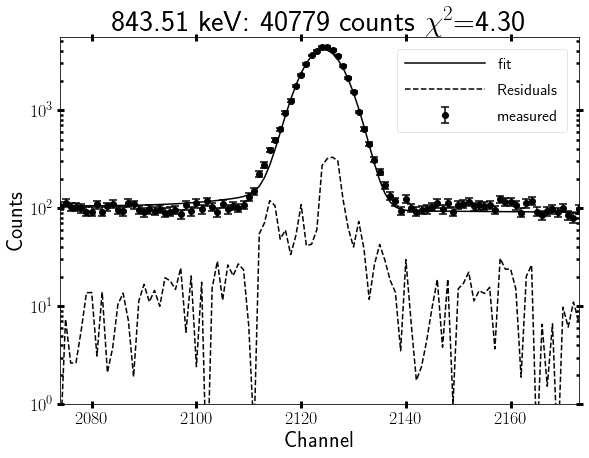

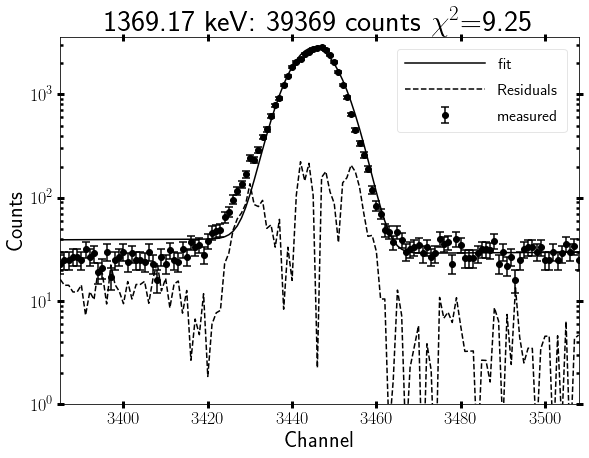


 Al1a
Energy  Peak Area
843.51   40779   201
1369.17   39368   198




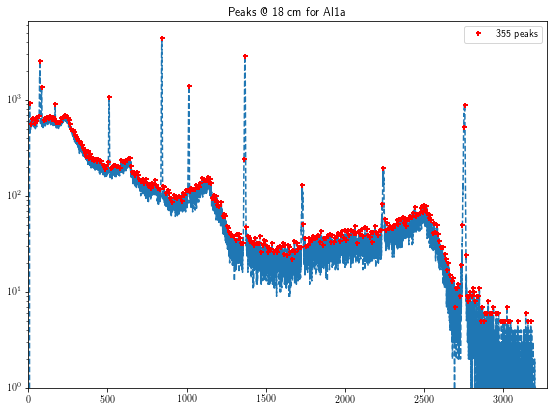

Al1b


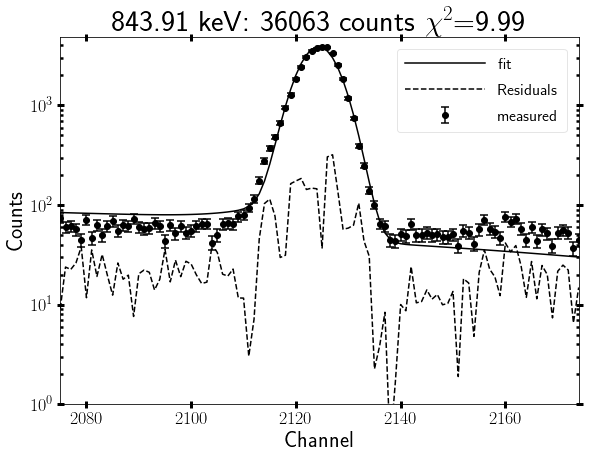

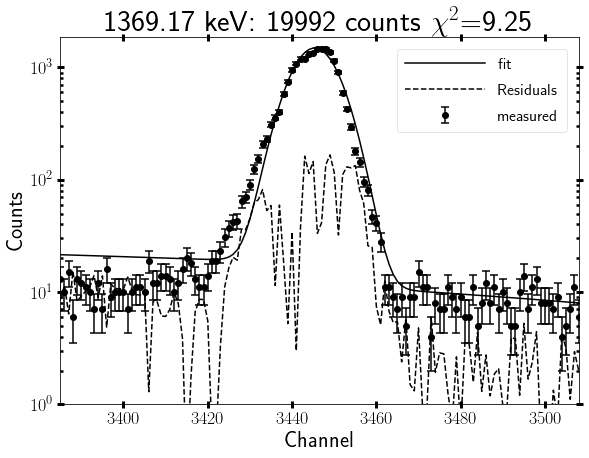


 Al1b
Energy  Peak Area
843.91   36063   189
1369.17   19992   141




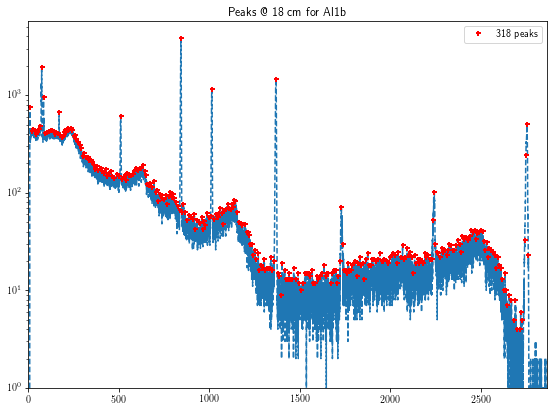

Au1


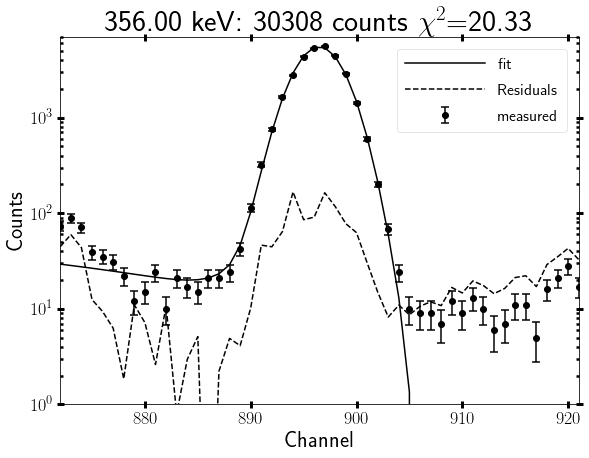

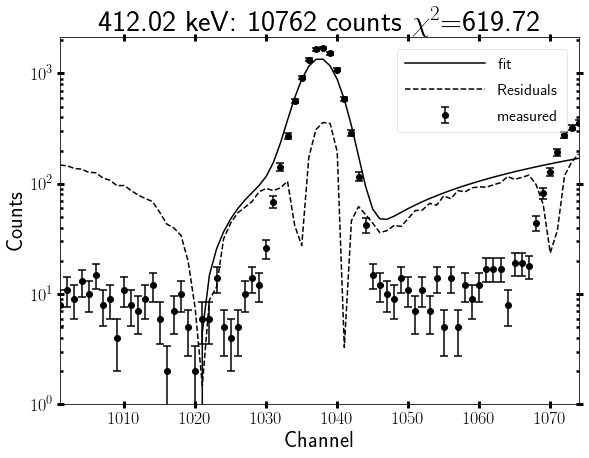


 Au1
Energy  Peak Area
356.00   30308   174
412.02   10761   103




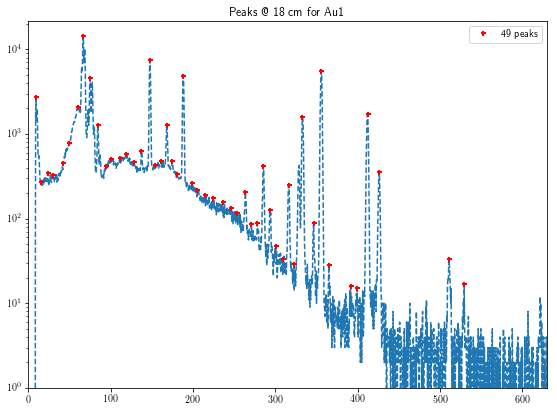

DU1

 DU1
Energy  Peak Area




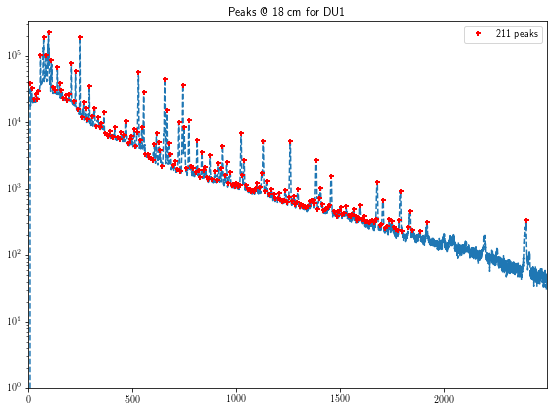

In1


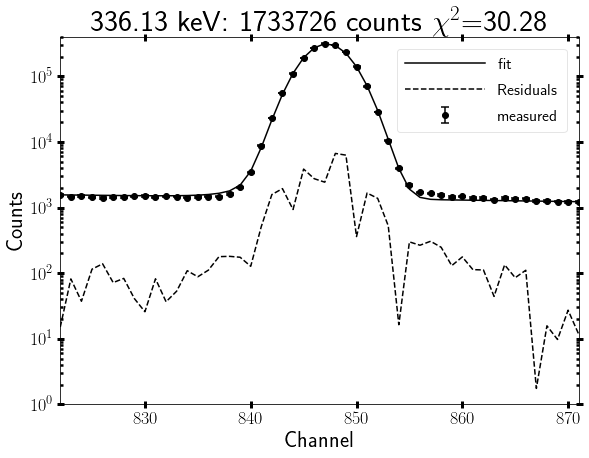

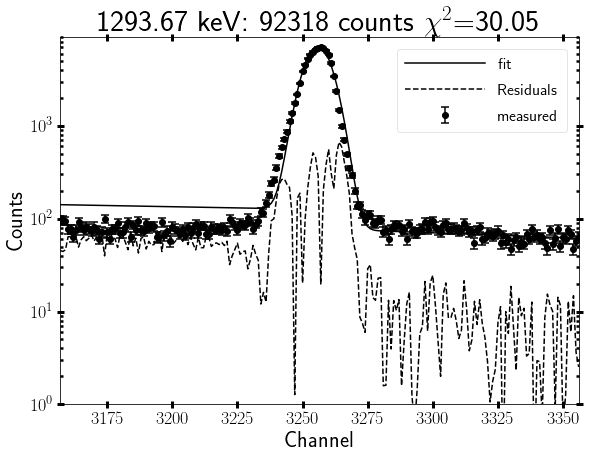


 In1
Energy  Peak Area
336.13   1733725   1316
1293.67   92318   303




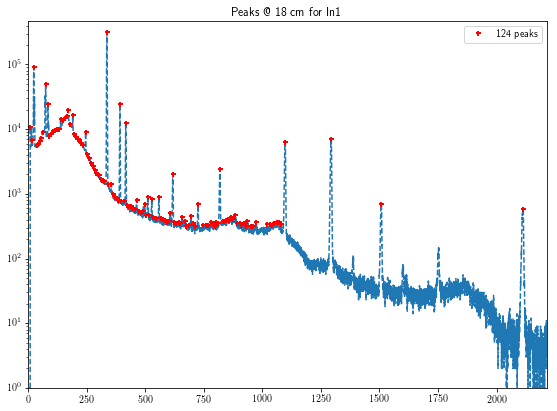

Ni1


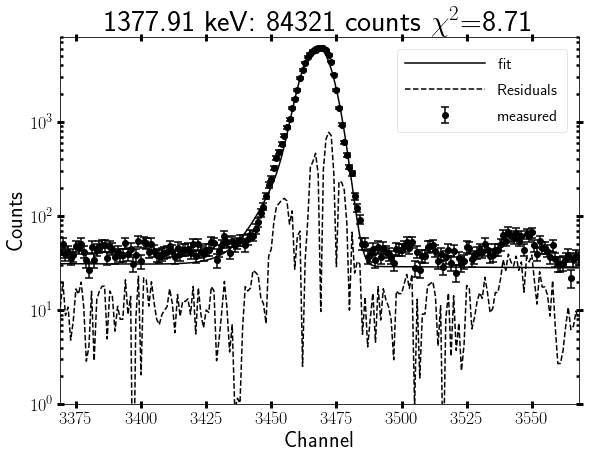

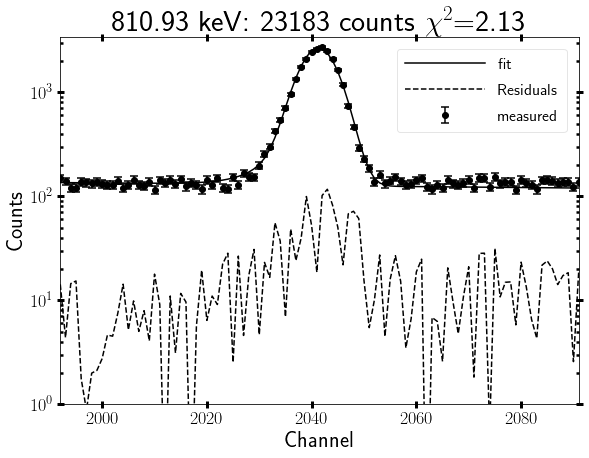


 Ni1
Energy  Peak Area
1377.91   84320   290
810.93   23183   152




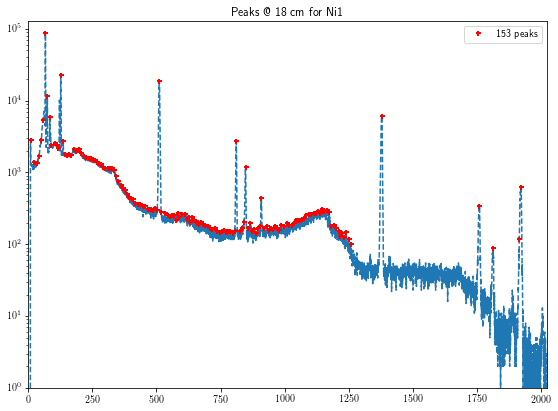

Zr1


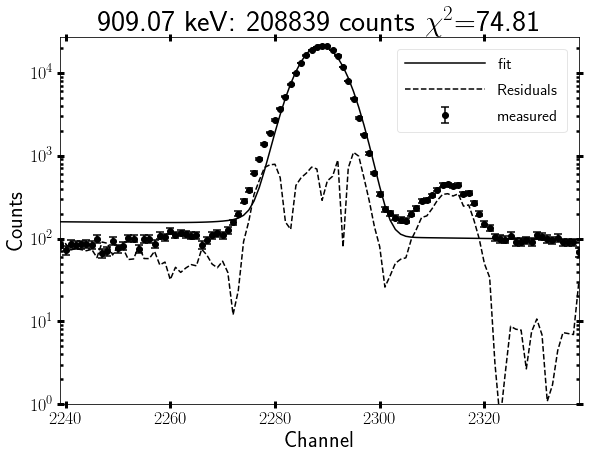


 Zr1
Energy  Peak Area
909.07   208839   456




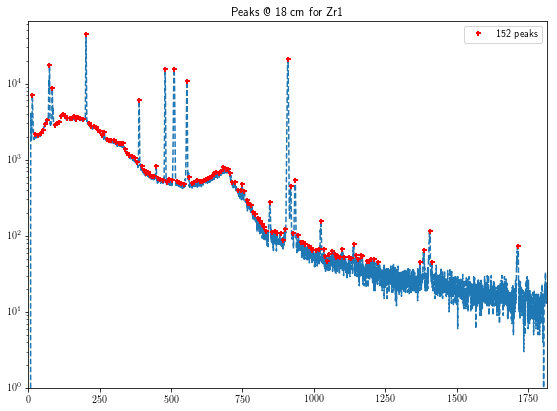

   isotope      line  branchingRatio  measuredCounts  measUncert
0     Al1b   843.760           71.80           36063         189
1     Al1b  1368.630           99.99           19992         141
2     Al1a   843.760           71.80           40779         201
3     Al1a  1368.630           99.99           39368         198
4      In1   336.241           45.80         1733725        1316
5      In1  1293.560           84.80           92318         303
6      Au1   355.700           80.90           30308         174
7      Au1   411.800           95.62           10761         103
8      Ni1  1377.630           81.70           84320         290
9      Ni1   810.760           99.45           23183         152
10     Zr1   909.150           99.04          208839         456

------------------------
Position = 1 cm
------------------------
Al1a


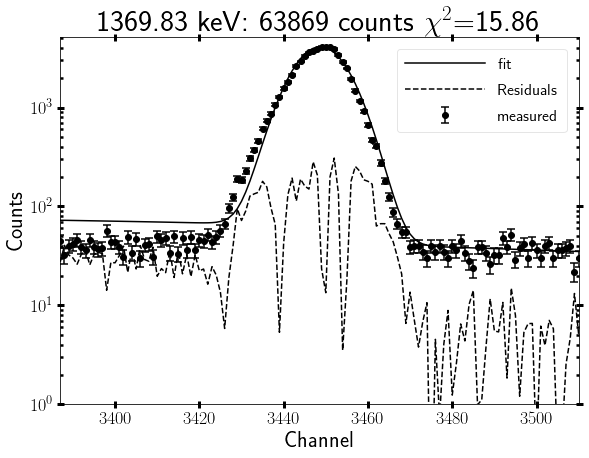


 Al1a
Energy  Peak Area
1369.83   63868   252




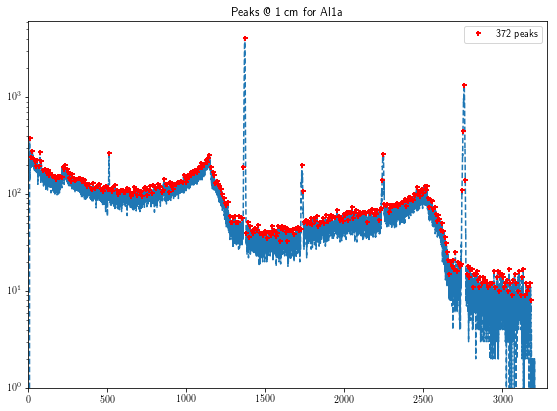

Al1b


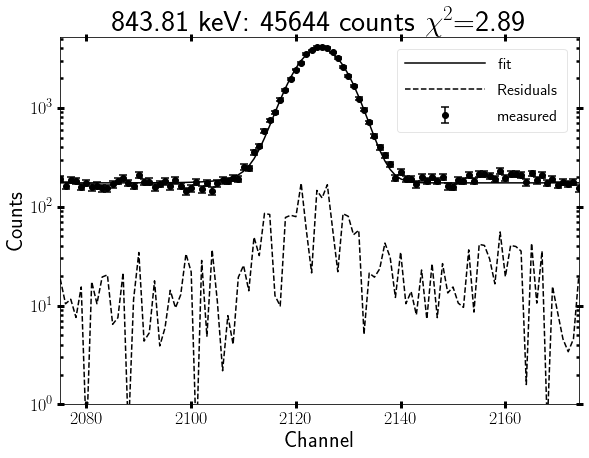

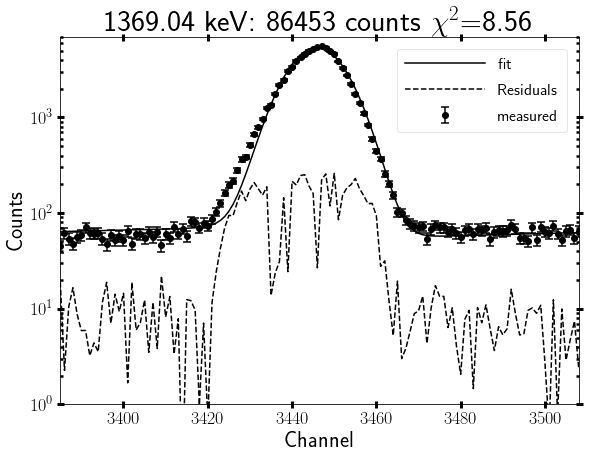


 Al1b
Energy  Peak Area
843.81   45644   213
1369.04   86452   294




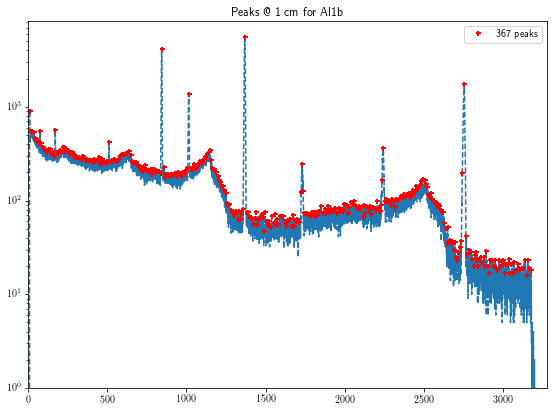

Au1


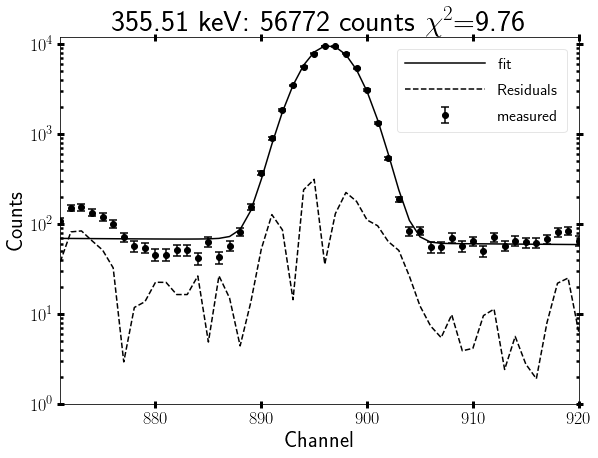

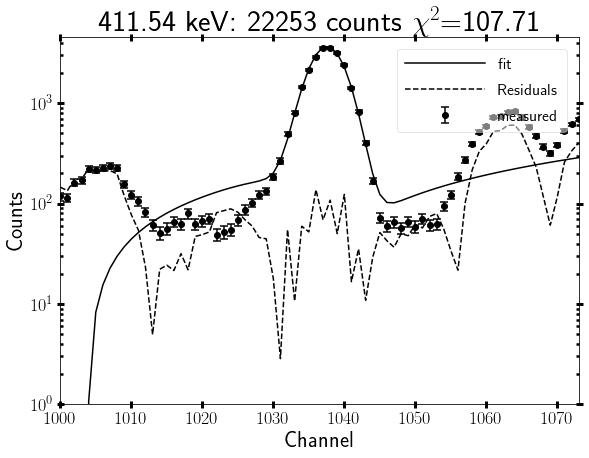


 Au1
Energy  Peak Area
355.51   56771   238
411.54   22253   149




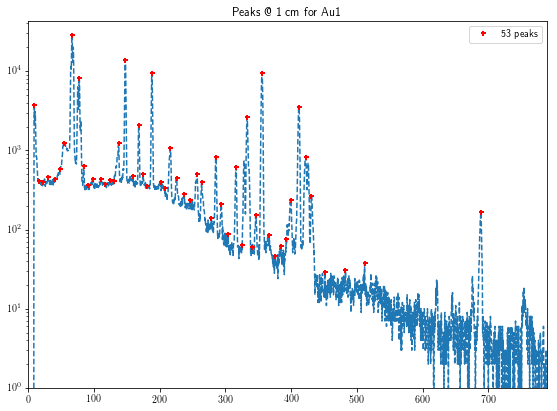

In1


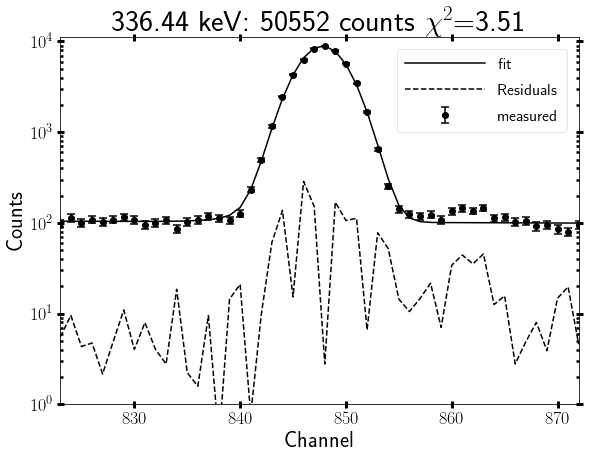


 In1
Energy  Peak Area
336.44   50552   224




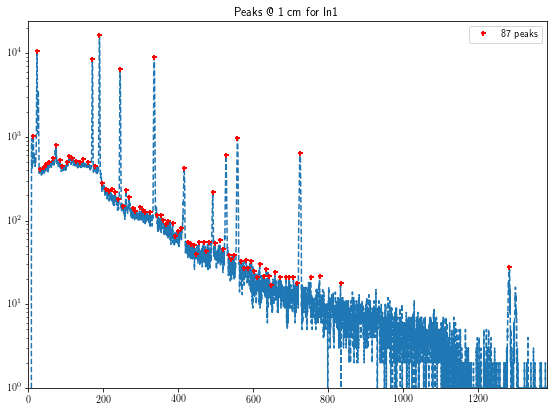

Ni1


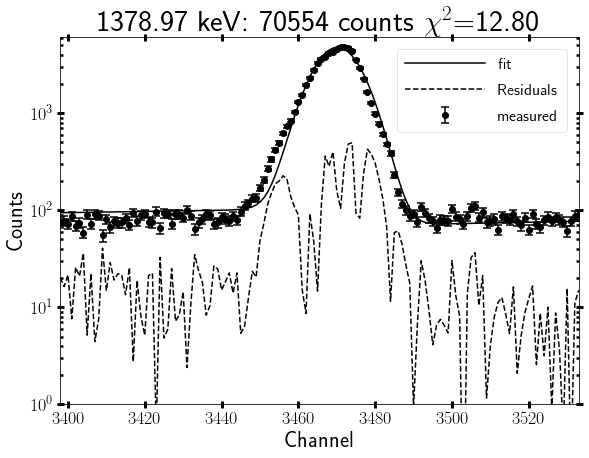

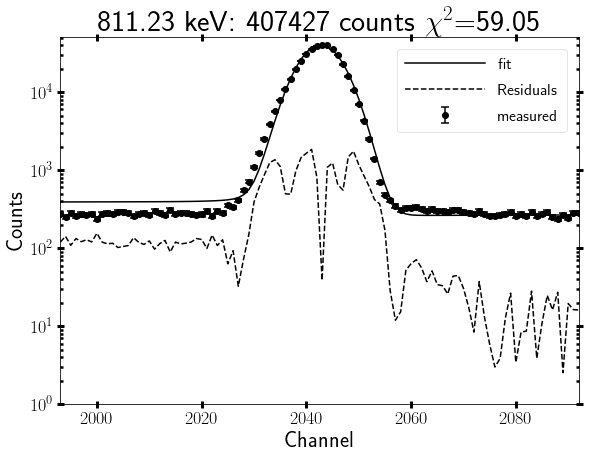


 Ni1
Energy  Peak Area
1378.97   70554   265
811.23   407426   638




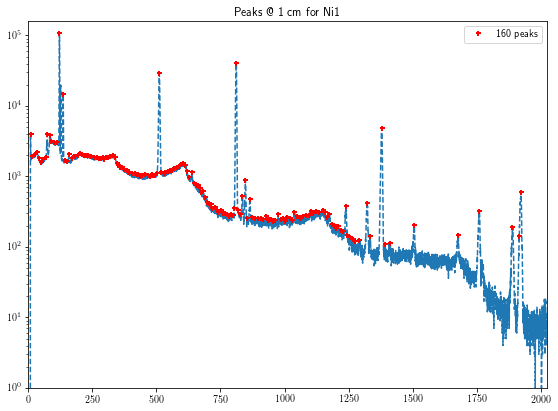

Zr1


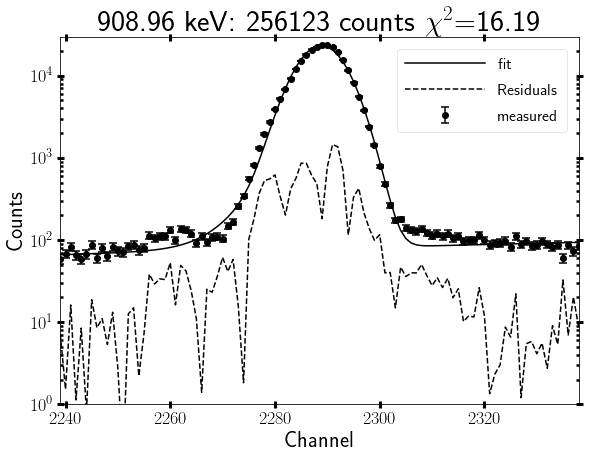


 Zr1
Energy  Peak Area
908.96   256122   506




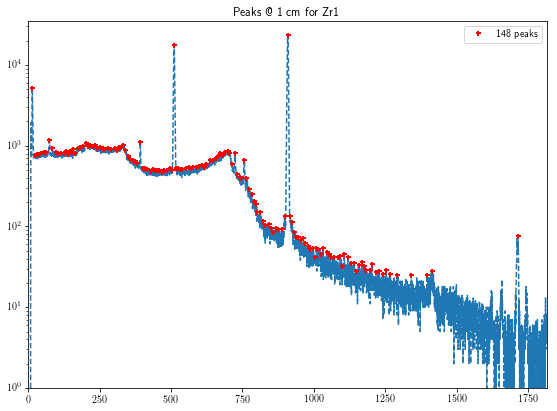

   isotope      line  branchingRatio  measuredCounts  measUncert
0     Al1b   843.760           71.80           45644         213
1     Al1b  1368.630           99.99           86452         294
2     Al1a   843.760           71.80               0           0
3     Al1a  1368.630           99.99           63868         252
4      In1   336.241           45.80           50552         224
5      In1  1293.560           84.80               0           0
6      Au1   355.700           80.90           56771         238
7      Au1   411.800           95.62           22253         149
8      Ni1  1377.630           81.70           70554         265
9      Ni1   810.760           99.45          407426         638
10     Zr1   909.150           99.04          256122         506

------------------------
Position = 5 cm
------------------------
Al1a


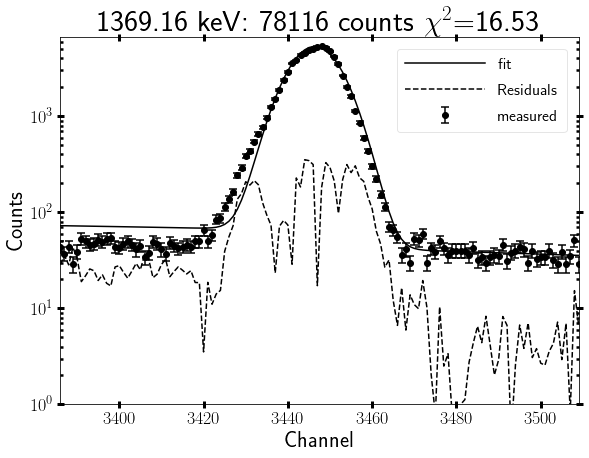


 Al1a
Energy  Peak Area
1369.16   78116   279




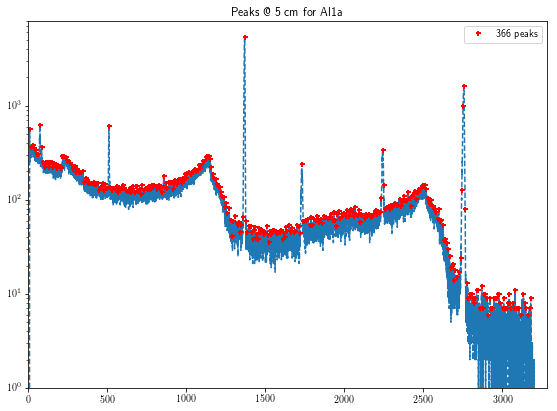

Al1b


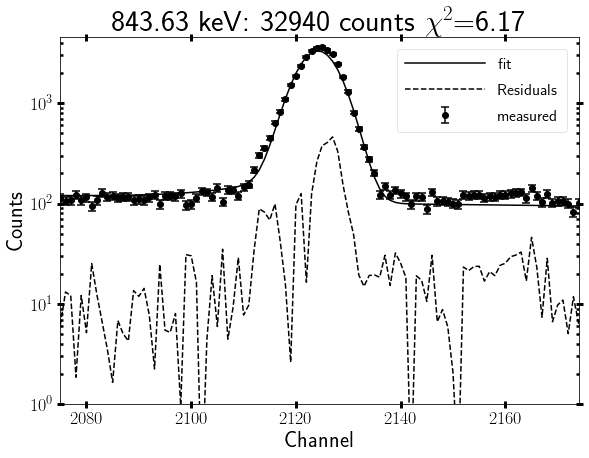

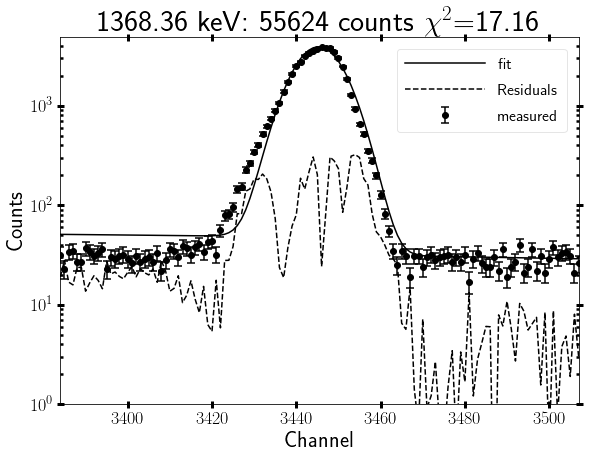


 Al1b
Energy  Peak Area
843.63   32940   181
1368.36   55624   235




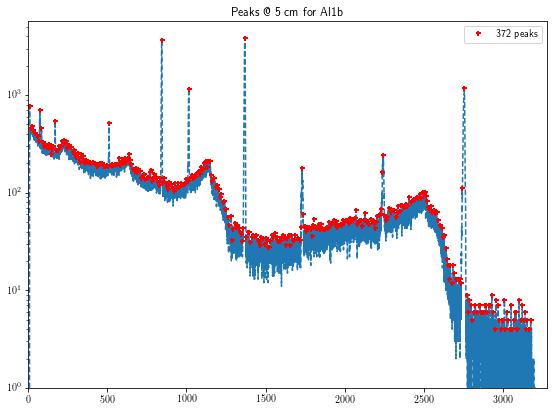

In1


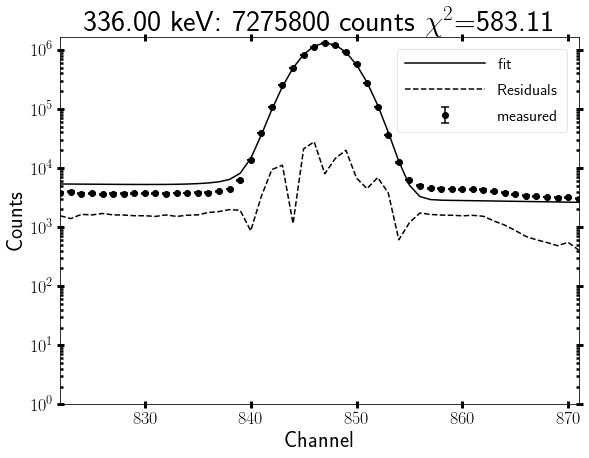


 In1
Energy  Peak Area
336.00   7275799   2697




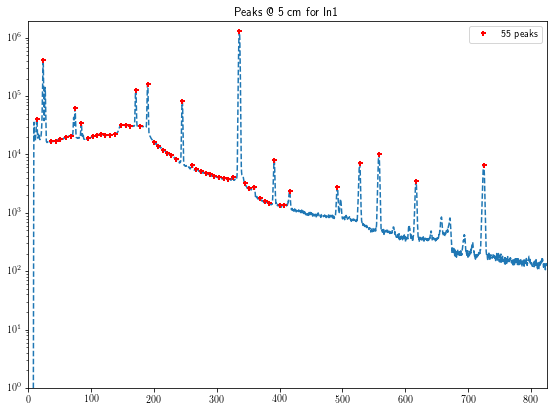

Ni1


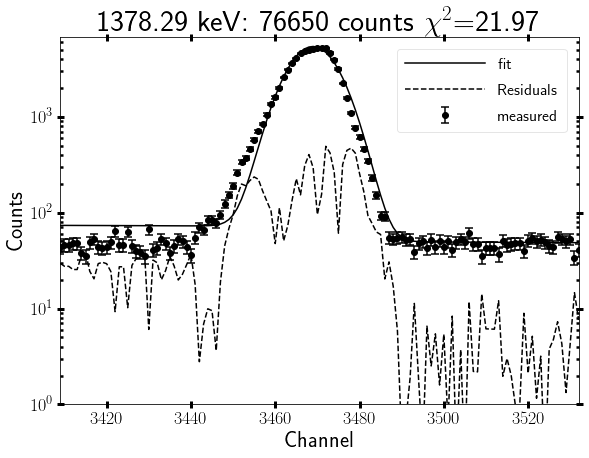

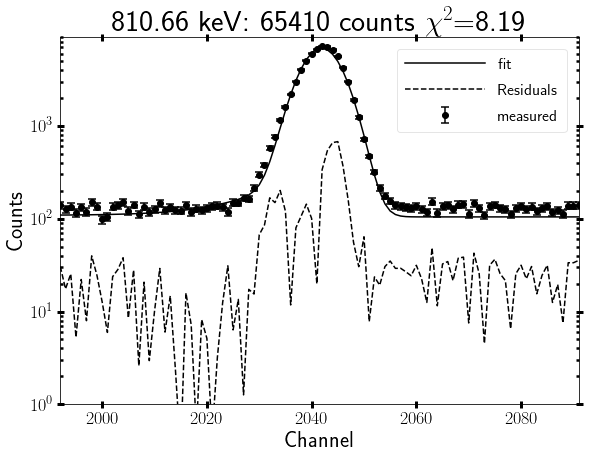


 Ni1
Energy  Peak Area
1378.29   76649   276
810.66   65410   255




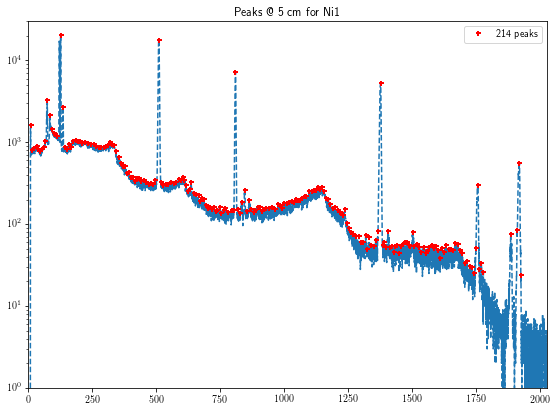

Zr1


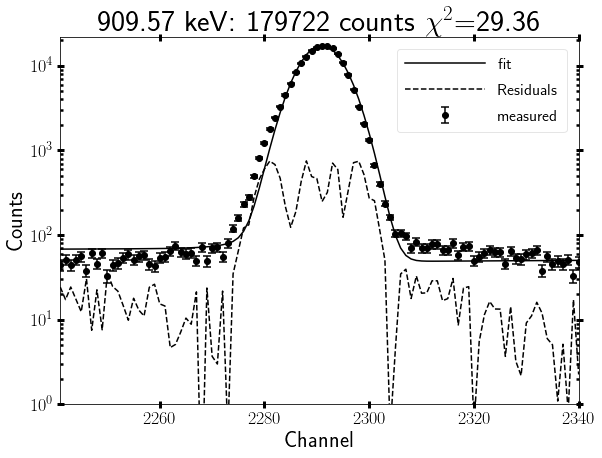


 Zr1
Energy  Peak Area
909.57   179722   423




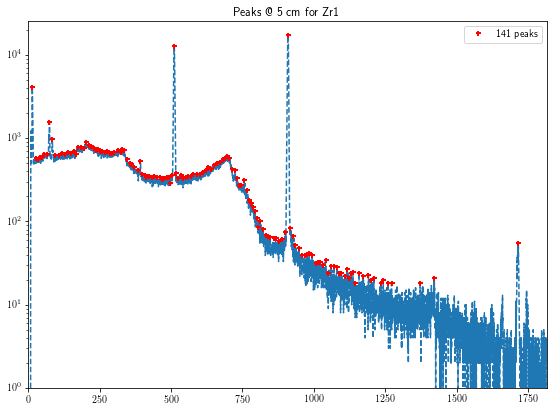

   isotope      line  branchingRatio  measuredCounts  measUncert
0     Al1b   843.760           71.80           32940         181
1     Al1b  1368.630           99.99           55624         235
2     Al1a   843.760           71.80               0           0
3     Al1a  1368.630           99.99           78116         279
4      In1   336.241           45.80         7275799        2697
5      In1  1293.560           84.80               0           0
6      Au1   355.700           80.90               0           0
7      Au1   411.800           95.62               0           0
8      Ni1  1377.630           81.70           76649         276
9      Ni1   810.760           99.45           65410         255
10     Zr1   909.150           99.04          179722         423

------------------------
Position = 10 cm
------------------------
Al1b


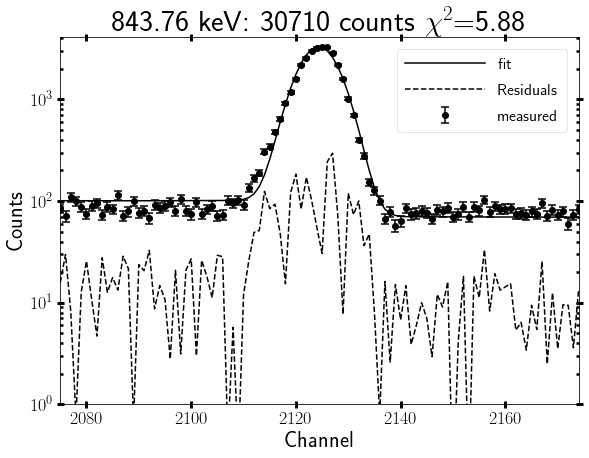

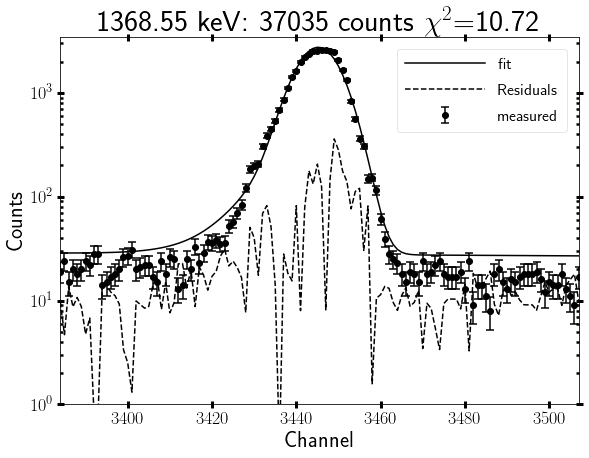


 Al1b
Energy  Peak Area
843.76   30709   175
1368.55   37034   192




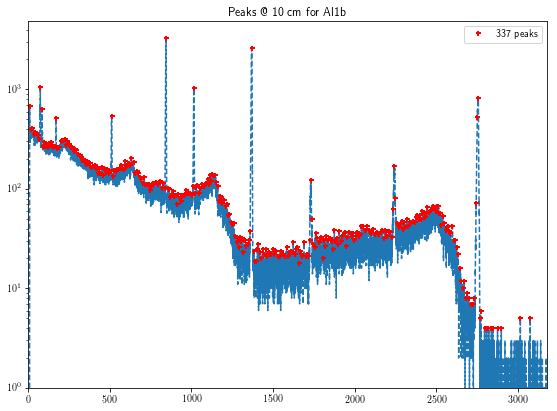

   isotope      line  branchingRatio  measuredCounts  measUncert
0     Al1b   843.760           71.80           30709         175
1     Al1b  1368.630           99.99           37034         192
2     Al1a   843.760           71.80               0           0
3     Al1a  1368.630           99.99               0           0
4      In1   336.241           45.80               0           0
5      In1  1293.560           84.80               0           0
6      Au1   355.700           80.90               0           0
7      Au1   411.800           95.62               0           0
8      Ni1  1377.630           81.70               0           0
9      Ni1   810.760           99.45               0           0
10     Zr1   909.150           99.04               0           0


In [22]:
# Create a dictionary of data frames to store each of the positional information
peakDataSet1 = {}
for p in posUsed1:
    print "\n------------------------"
    print "Position = {} cm".format(p)
    print "------------------------"
    
    # Update dataframe to store calculated peak information
    linesSet1['measuredCounts'] = 0     
    linesSet1['measUncert'] = 0
    
    for column in data1[p]:    
        # Find the peaks and set the windows
        channels = np.asarray(data1[p].index)
        counts = np.asarray(data1[p][column]).astype(float)
        energy = eCalibParams[p][2]+eCalibParams[p][1]*channels+eCalibParams[p][0]*channels**2
        peaks = peakutils.indexes(counts, thres=0.001, min_dist=15)
        windows = get_peak_windows(peaks, minWindow=25, peakWidth=10, adaptive=True)
    
        
        # Loop over all identified peaks to compare against calibration points loaded previously
        print data1[p][column].name
        output = "\n {}\nEnergy  Peak Area\n".format(data1[p][column].name)      
        for i in range(len(linesSet1['line'])):
            for e, pk in zip(energy[peaks], peaks):
                
                # THE FOLLOWING LOOP SKIPS OVER Al1, 843.76keV at 1cm
                if p != 1 or linesSet1['isotope'][i] != 'Al1a' or linesSet1['line'][i] > 1000:
                # Calculate the total peak counts if a calibration peak
                    if abs(e-linesSet1['line'][i]) < 1.5 and data1[p][column].name.strip() == linesSet1['isotope'][i].strip():
                        pkChannels = channels[int(windows[pk][0]):int(windows[pk][1])]
                        pkCounts = counts[windows[pk][0]:windows[pk][1]]
                        (linesSet1.at[i, 'measuredCounts'], linesSet1.at[i, 'measUncert'], redChiSq) = \
                                     ge_peakfit(pkChannels, pkCounts, plotComp=True, plotTitle='{:.2f} keV'.format(e))
                        #pause()    
                        output = output + "{:.2f}   {:.0f}   {:.0f}\n".format(e, linesSet1.at[i, 'measuredCounts'],
                                                                          linesSet1.at[i, 'measUncert'])
            linesSet1.at[i, 'isotope'] = linesSet1.at[i, 'isotope'].strip()
        print output + "\n"
        
        # Plot the peaks found
        fig = pyplot.figure(figsize=(9,6))
        ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.85])
        ax1.set_yscale('log')
        ax1.axis([0, energy[peaks[-1]]+100, 1, max(counts*1.5)])
        pplot(energy, counts, peaks)
        pyplot.title('Peaks @ {} cm for {}'.format(p,data1[p][column].name))        
        pyplot.show()
        
    print linesSet1
    peakDataSet1[p] = cp.deepcopy(linesSet1)

### Data Set 2

#### Import Data Set 2

In [23]:
#DataSet2Path = "/Users/zacharysweger/Desktop/BANG/Bevins_33MeVTa_25Apr/Data/2/"
DataSet2Path = os.path.abspath('BeamOnlyData')

# Variables to allow for multiple positions to be handled at once
posSet2 = False
posUsed2 = []

# Storage for parameters that vary by position
liveTime2 = {}
data2 = {}

# Loop over all files
for filename in os.listdir(DataSet2Path):
    if filename.endswith(".Spe"): 
        name = os.path.splitext(filename)[0]
        
        # Read data from this file
        print "Processing:", filename
        (time, t, measDate, a, b, c, tmpData) = parse_spe(DataSet2Path+'/'+filename)
        # Determine position, update data structures if necessary, and store data
        position = int(name.split('_')[1])
        if position not in posUsed2:
            posUsed2.append(position)
            liveTime2[position] = {}
            data2[position] = tmpData
            data2[position].columns = [name.split('_')[0]]
        else: 
            data2[position].loc[:,name.split('_')[0]] = tmpData['counts']
            #sources.at[name.split('_')[0], 'measDate'] = measDate
            liveTime2[position][name.split('_')[0]] = time

for p in posUsed2:
    print "\nPosition = {} cm".format(p)
    print "LiveTime:", liveTime2[p]
    print data2[p].head(3)

Processing: Al2_1_26April17.Spe
Processing: Au2_1_26April17.Spe
Processing: In2_1_26April17.Spe
Processing: Ni2_1_27Apr17_1200.Spe
Processing: Zr2_1_26April17.Spe

Position = 1 cm
LiveTime: {'Ni2': 44067.0, 'Au2': 8500.0, 'Zr2': 7625.0, 'In2': 2809.0}
   Al2  Au2  In2  Ni2  Zr2
0    0    0    0    0    0
1    0    0    0    0    0
2    0    0    0    0    0


#### Import Expected Peak Data

In [24]:
linesSet2 = pd.read_excel(simFoilPath, sheetname='DataSet2', usecols=["Foil", "Gamma E [kev]", "BR"])
linesSet2.columns=['isotope','line','branchingRatio']
print "The peak data is: \n\n", linesSet2

The peak data is: 

  isotope      line  branchingRatio
0     Al2   843.760           71.80
1     Al2  1368.630           99.99
2     In2   336.241           45.80
3     In2  1293.560           84.80
4     Au2   355.700           80.90
5     Au2   411.800           95.62
6     Ni2  1377.630           81.70
7     Ni2   810.760           99.45
8     Zr2   909.150           99.04



------------------------
Position = 1 cm
------------------------
Al2


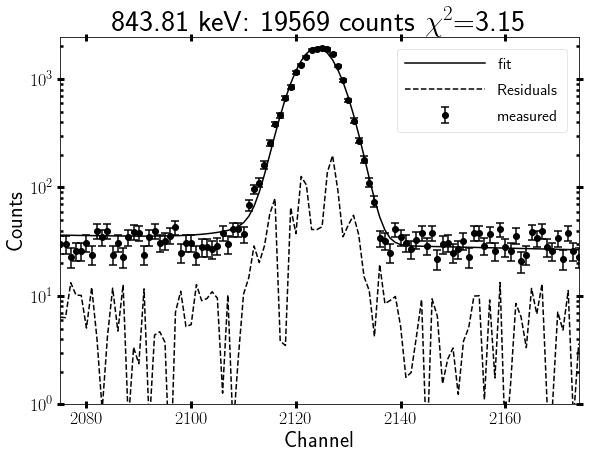

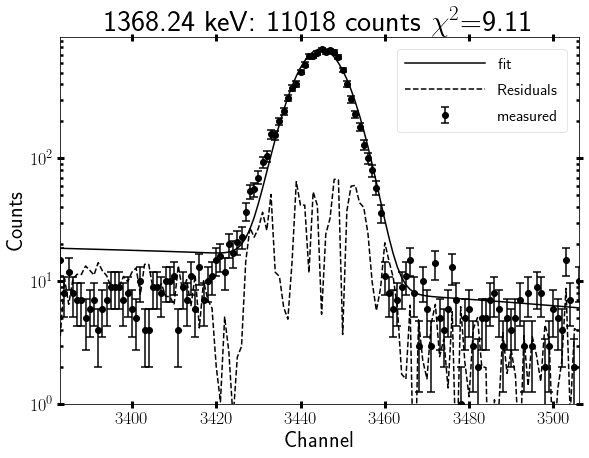


 Al2
Energy  Peak Area
843.81   19568   139
1368.24   11018   104




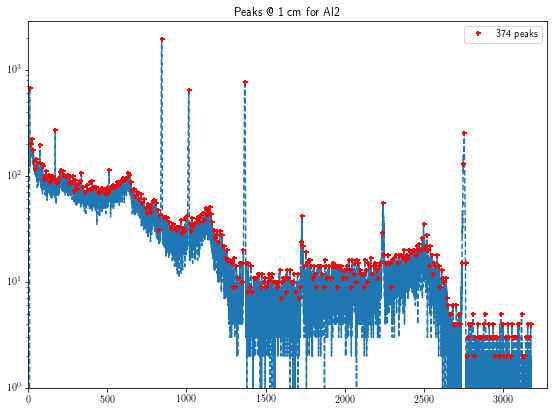

Au2


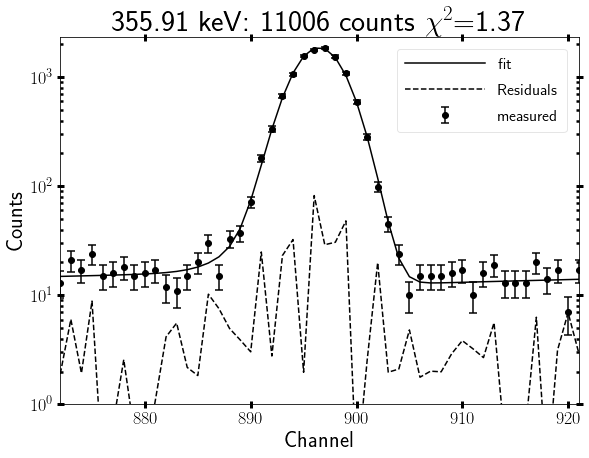

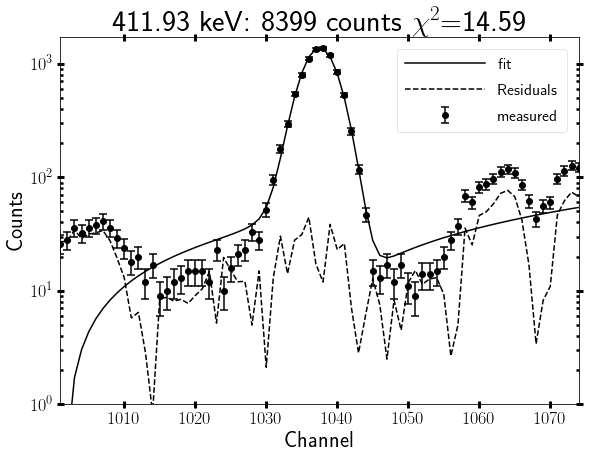


 Au2
Energy  Peak Area
355.91   11005   104
411.93   8399   91




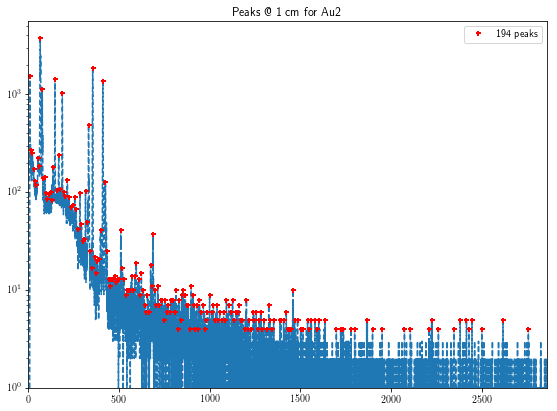

In2


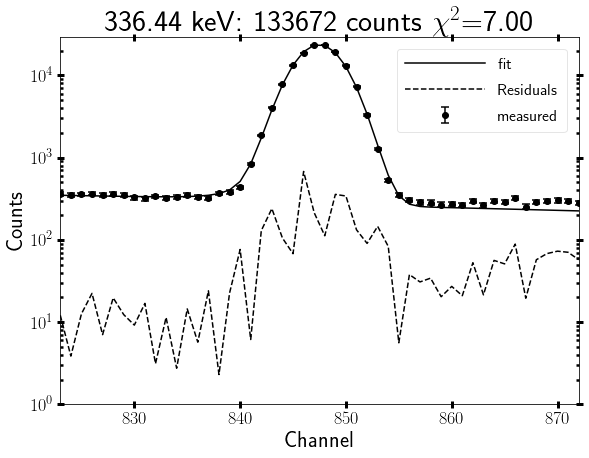

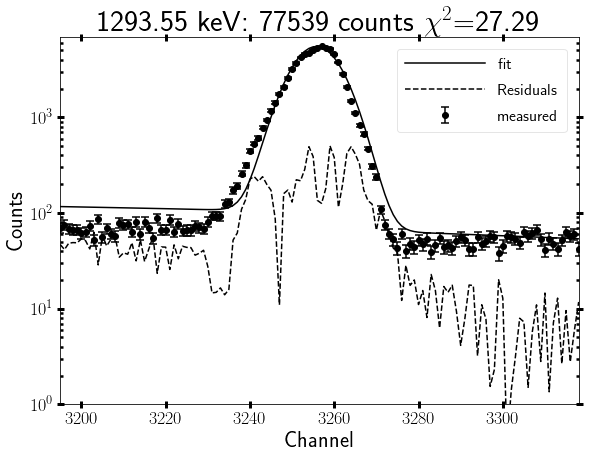


 In2
Energy  Peak Area
336.44   133672   365
1293.55   77538   278




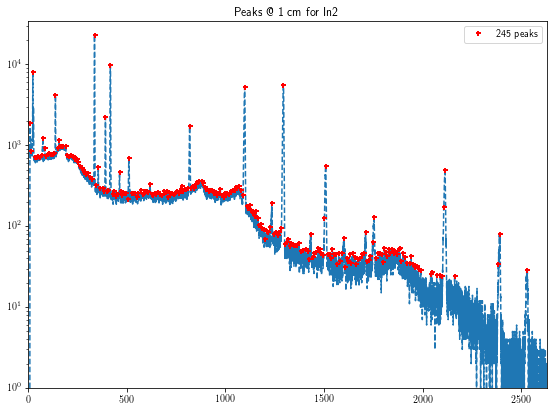

Ni2


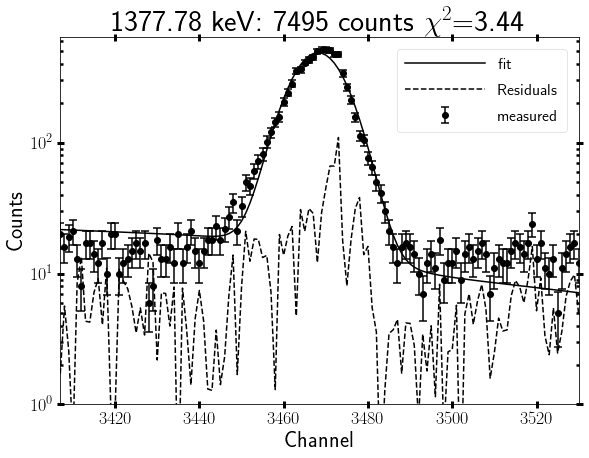

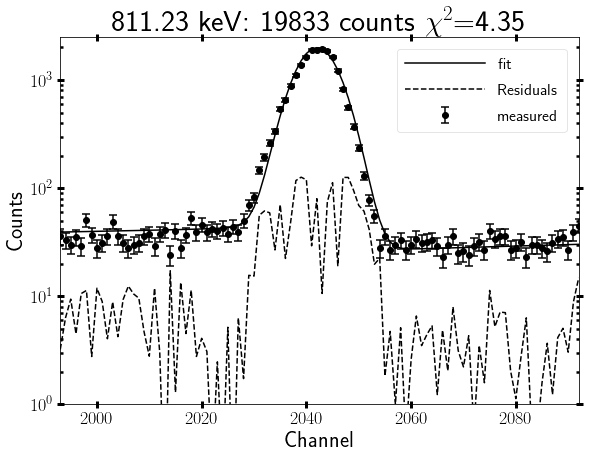


 Ni2
Energy  Peak Area
1377.78   7495   86
811.23   19832   140




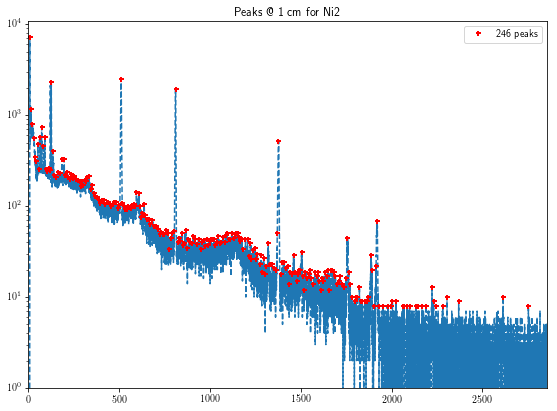

Zr2


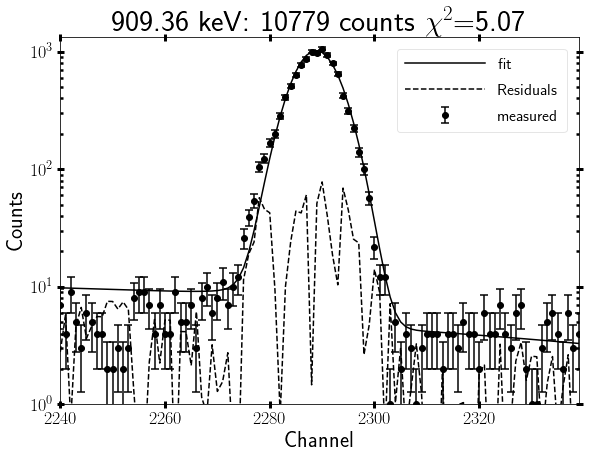


 Zr2
Energy  Peak Area
909.36   10778   103




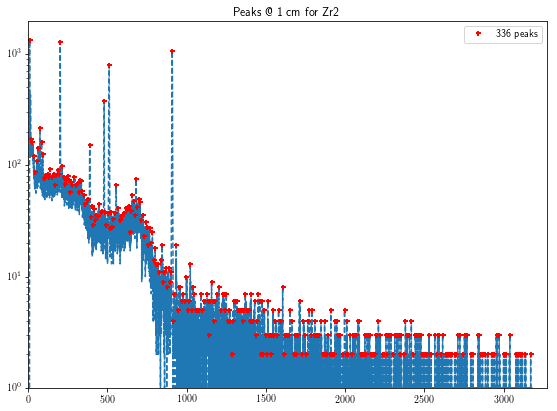

  isotope      line  branchingRatio  measuredCounts  measUncert
0     Al2   843.760           71.80           19568         139
1     Al2  1368.630           99.99           11018         104
2     In2   336.241           45.80          133672         365
3     In2  1293.560           84.80           77538         278
4     Au2   355.700           80.90           11005         104
5     Au2   411.800           95.62            8399          91
6     Ni2  1377.630           81.70            7495          86
7     Ni2   810.760           99.45           19832         140
8     Zr2   909.150           99.04           10778         103


In [25]:
# Create a dictionary of data frames to store each of the positional information
peakDataSet2 = {}
for p in posUsed2:
    print "\n------------------------"
    print "Position = {} cm".format(p)
    print "------------------------"
    
    # Update dataframe to store calculated peak information
    linesSet2['measuredCounts'] = 0     
    linesSet2['measUncert'] = 0
    
    for column in data2[p]:    
        # Find the peaks and set the windows
        channels = np.asarray(data2[p].index)
        counts = np.asarray(data2[p][column]).astype(float)
        energy = eCalibParams[p][2]+eCalibParams[p][1]*channels+eCalibParams[p][0]*channels**2
        peaks = peakutils.indexes(counts, thres=0.001, min_dist=15)
        windows = get_peak_windows(peaks, minWindow=25, peakWidth=10, adaptive=True)
        
        # Loop over all identified peaks to compare against calibration points loaded previously
        print data2[p][column].name
        output = "\n {}\nEnergy  Peak Area\n".format(data2[p][column].name)      
        for i in range(len(linesSet2['line'])):
            for e, pk in zip(energy[peaks], peaks):
                # Calculate the total peak counts if a calibration peak
                if abs(e-linesSet2['line'][i]) < 1.5 and data2[p][column].name.strip() == linesSet2['isotope'][i].strip():
                    pkChannels = channels[int(windows[pk][0]):int(windows[pk][1])]
                    pkCounts = counts[windows[pk][0]:windows[pk][1]]
                    (linesSet2.at[i, 'measuredCounts'], linesSet2.at[i, 'measUncert'], redChiSq) = \
                                 ge_peakfit(pkChannels, pkCounts, plotComp=True, plotTitle='{:.2f} keV'.format(e))
                    #pause()    
                    output = output + "{:.2f}   {:.0f}   {:.0f}\n".format(e, linesSet2.at[i, 'measuredCounts'],
                                                                          linesSet2.at[i, 'measUncert'])
            linesSet2.at[i, 'isotope'] = linesSet2.at[i, 'isotope'].strip()
        print output + "\n"
        
        # Plot the peaks found
        fig = pyplot.figure(figsize=(9,6))
        ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.85])
        ax1.set_yscale('log')
        ax1.axis([0, energy[peaks[-1]]+100, 1, max(counts*1.5)])
        pplot(energy, counts, peaks)
        pyplot.title('Peaks @ {} cm for {}'.format(p,data2[p][column].name))        
        pyplot.show()
        
    print linesSet2
    peakDataSet2[p] = cp.deepcopy(linesSet2)

### Data Set 3

In [26]:
#DataSet3Path = "/Users/zacharysweger/Desktop/BANG/Bevins_33MeVTa_25Apr/Data/3/"
DataSet3Path = os.path.abspath('ETAData')

# Variables to allow for multiple positions to be handled at once
posSet3 = False
posUsed3 = []

# Storage for parameters that vary by position
liveTime3 = {}
data3 = {}

# Loop over all files
for filename in os.listdir(DataSet3Path):
    if filename.endswith(".Spe"): 
        name = os.path.splitext(filename)[0]
        
        # Read data from this file
        print "Processing:", filename
        (time, t, measDate, a, b, c, tmpData) = parse_spe(DataSet3Path+'/'+filename)
        # Determine position, update data structures if necessary, and store data
        position = int(name.split('_')[1])
        if position not in posUsed3:
            posUsed3.append(position)
            liveTime3[position] = {}
            data3[position] = tmpData
            data3[position].columns = [name.split('_')[0]]
        else: 
            data3[position].loc[:,name.split('_')[0]] = tmpData['counts']
            #sources.at[name.split('_')[0], 'measDate'] = measDate
            liveTime3[position][name.split('_')[0]] = time

for p in posUsed3:
    print "\nPosition = {} cm".format(p)
    print "LiveTime:", liveTime3[p]
    print data3[p].head(3)

Processing: Al3_1_27Apr17.Spe
Processing: Au3_1_27Apr17.Spe
Processing: In3_1_27Apr17.Spe
Processing: Ni3_1_27Apr17.Spe
Processing: Zr3_1_27Apr17.Spe

Position = 1 cm
LiveTime: {'Ni3': 22546.0, 'Au3': 3091.0, 'Zr3': 2708.0, 'In3': 566.0}
   Al3  Au3  In3  Ni3  Zr3
0    0    0    0    0    0
1    0    0    0    0    0
2    0    0    0    0    0


In [27]:
linesSet3 = pd.read_excel(simFoilPath, sheetname='DataSet3', usecols=["Foil", "Gamma E [kev]", "BR"])
linesSet3.columns=['isotope','line','branchingRatio']
print "The peak data is: \n\n", linesSet3

The peak data is: 

  isotope      line  branchingRatio
0     Al3   843.760           71.80
1     Al3  1368.630           99.99
2     In3   336.241           45.80
3     In3  1293.560           84.80
4     Au3   355.700           80.90
5     Au3   411.800           95.62
6     Ni3  1377.630           81.70
7     Ni3   810.760           99.45
8     Zr3   909.150           99.04



------------------------
Position = 1 cm
------------------------
Al3


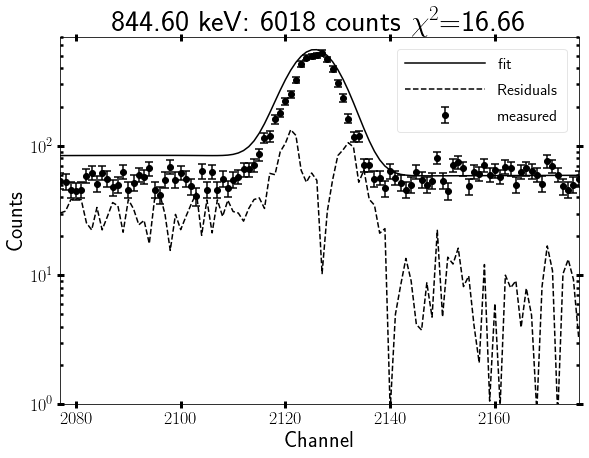

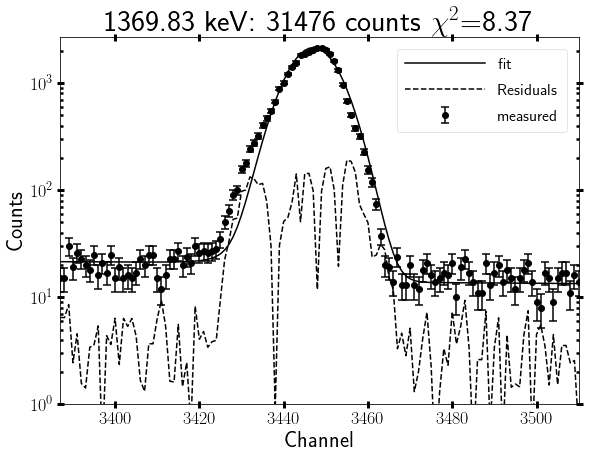


 Al3
Energy  Peak Area
844.60   6018   77
1369.83   31476   177




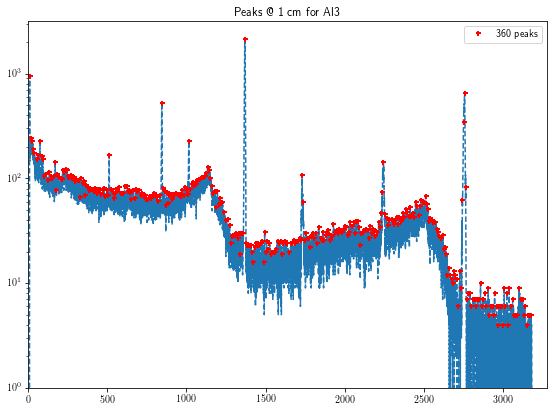

Au3


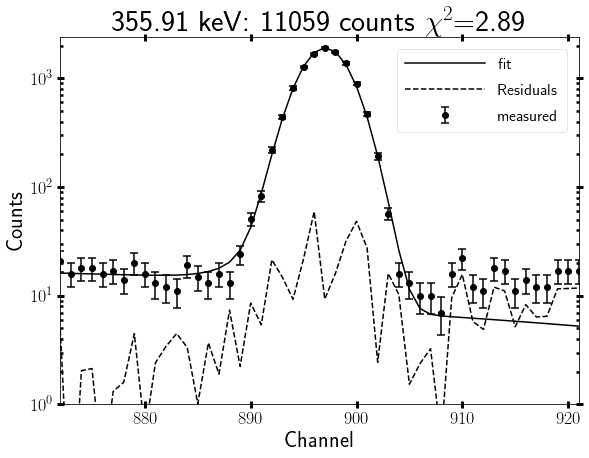

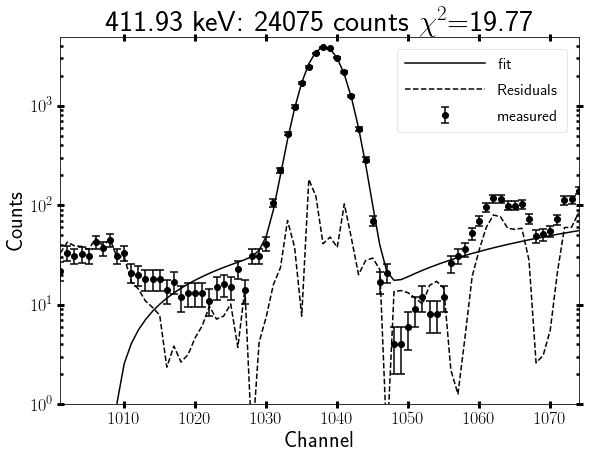


 Au3
Energy  Peak Area
355.91   11059   105
411.93   24075   155




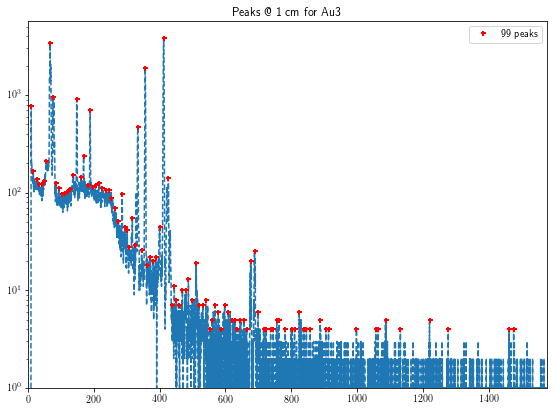

In3


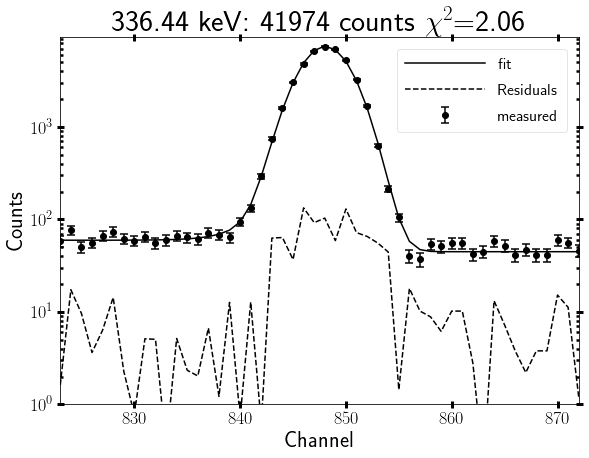

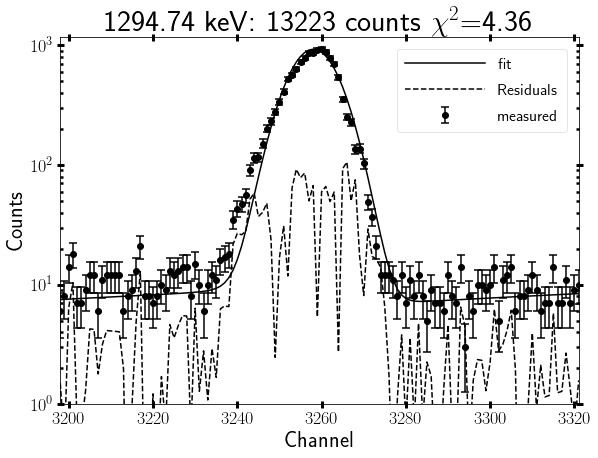


 In3
Energy  Peak Area
336.44   41974   204
1294.74   13222   114




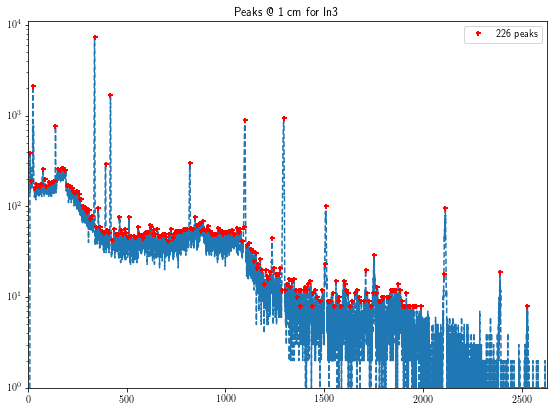

Ni3


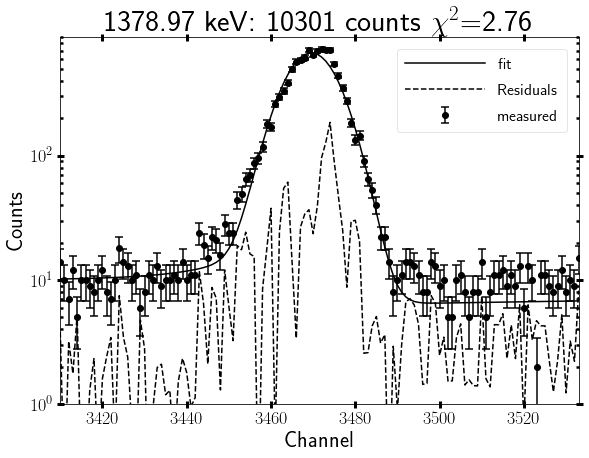

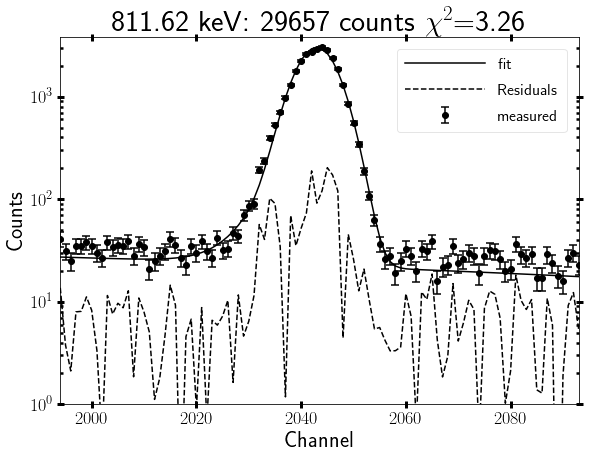


 Ni3
Energy  Peak Area
1378.97   10301   101
811.62   29656   172




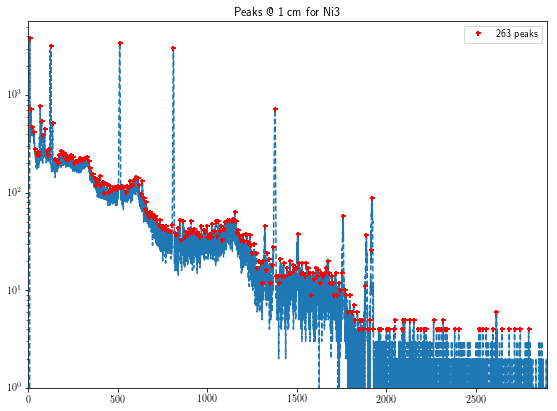

Zr3


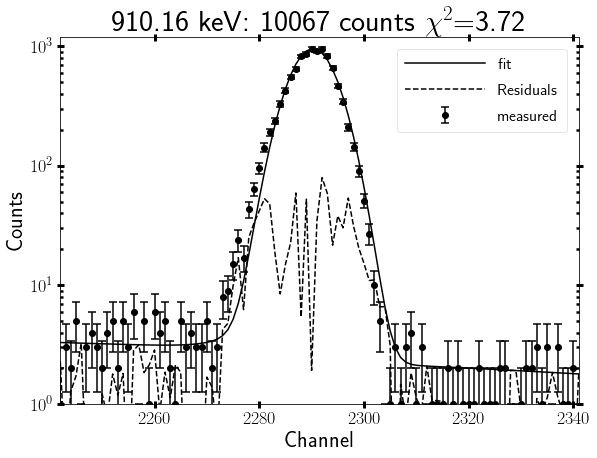


 Zr3
Energy  Peak Area
910.16   10066   100




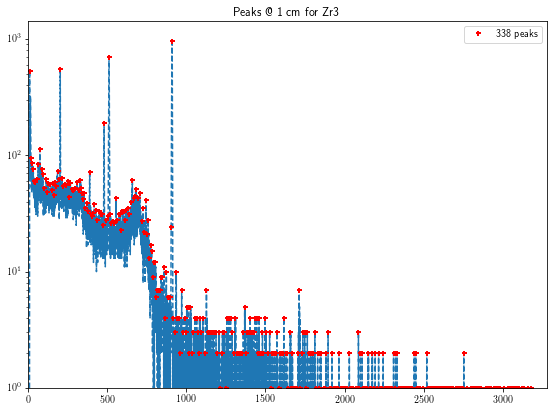

  isotope      line  branchingRatio  measuredCounts  measUncert
0     Al3   843.760           71.80            6018          77
1     Al3  1368.630           99.99           31476         177
2     In3   336.241           45.80           41974         204
3     In3  1293.560           84.80           13222         114
4     Au3   355.700           80.90           11059         105
5     Au3   411.800           95.62           24075         155
6     Ni3  1377.630           81.70           10301         101
7     Ni3   810.760           99.45           29656         172
8     Zr3   909.150           99.04           10066         100


In [28]:
# Create a dictionary of data frames to store each of the positional information
peakDataSet3 = {}
for p in posUsed3:
    print "\n------------------------"
    print "Position = {} cm".format(p)
    print "------------------------"
    
    # Update dataframe to store calculated peak information
    linesSet3['measuredCounts'] = 0     
    linesSet3['measUncert'] = 0
    
    for column in data3[p]:    
        # Find the peaks and set the windows
        channels = np.asarray(data3[p].index)
        counts = np.asarray(data3[p][column]).astype(float)
        energy = eCalibParams[p][2]+eCalibParams[p][1]*channels+eCalibParams[p][0]*channels**2
        peaks = peakutils.indexes(counts, thres=0.001, min_dist=15)
        windows = get_peak_windows(peaks, minWindow=25, peakWidth=10, adaptive=True)
        
        # Loop over all identified peaks to compare against calibration points loaded previously
        print data3[p][column].name
        output = "\n {}\nEnergy  Peak Area\n".format(data3[p][column].name)      
        for i in range(len(linesSet3['line'])):
            for e, pk in zip(energy[peaks], peaks):
                # Calculate the total peak counts if a calibration peak
                if abs(e-linesSet3['line'][i]) < 1.5 and data3[p][column].name.strip() == linesSet3['isotope'][i].strip():
                    pkChannels = channels[int(windows[pk][0]):int(windows[pk][1])]
                    pkCounts = counts[windows[pk][0]:windows[pk][1]]
                    (linesSet3.at[i, 'measuredCounts'], linesSet3.at[i, 'measUncert'], redChiSq) = \
                                 ge_peakfit(pkChannels, pkCounts, plotComp=True, plotTitle='{:.2f} keV'.format(e))
                    #pause()    
                    output = output + "{:.2f}   {:.0f}   {:.0f}\n".format(e, linesSet3.at[i, 'measuredCounts'],
                                                                          linesSet3.at[i, 'measUncert'])
            linesSet3.at[i, 'isotope'] = linesSet3.at[i, 'isotope'].strip()
        print output + "\n"
        
        # Plot the peaks found
        fig = pyplot.figure(figsize=(9,6))
        ax1 = fig.add_axes([0.1, 0.1, 0.8, 0.85])
        ax1.set_yscale('log')
        ax1.axis([0, energy[peaks[-1]]+100, 1, max(counts*1.5)])
        pplot(energy, counts, peaks)
        pyplot.title('Peaks @ {} cm for {}'.format(p,data3[p][column].name))        
        pyplot.show()
        
    print linesSet3
    peakDataSet3[p] = cp.deepcopy(linesSet3)